In [1]:
import pickle as pck
import matplotlib.pyplot as plt
import numpy as np
# from scipy.optimize import curve_fit
# import pylandau as pland
# import ROOT
import sys
import pandas as pd

from ROOT import TFile, TTree, TF1, TH1F, TCanvas, TLine, TLegend
from array import array


def Landau(x,a, MP,xi):
    C1 = a/np.sqrt((2 * np.pi))
    C2 = np.exp(-((x-MP)-1)/xi)
    C3 = np.exp((-0.5 * (((x-MP)-1)/xi + C2 )))
    return  C1 * C3

def Landgauss(x,a, MP, xi, b,eps):
    C1 = a/np.sqrt((2 * np.pi))
    C2 = np.exp(-((x-MP)-1)/xi)
    C3 = np.exp((-0.5 * (((x-MP)-1)/xi + C2 )))
    C4 = C1 * C3
    C5 = b * np.exp(-x/eps)
    return  C4 + C5

In [2]:
## Configuración del estilo de las imágenes
plt.rcParams.update({
    "image.origin": "lower",
    "image.aspect": 1,
    #"text.usetex": True,
    "grid.alpha": .5,
    "axes.linewidth":2,
    "lines.linewidth" : 1,
    "font.size":    15.0,
    "xaxis.labellocation": 'right',  # alignment of the xaxis label: {left, right, center}
    "yaxis.labellocation": 'top',  # alignment of the yaxis label: {bottom, top, center}
    "xtick.top":           True ,  # draw ticks on the top side
    "xtick.major.size":    8    ,# major tick size in points
    "xtick.minor.size":    4      ,# minor tick size in points
    "xtick.direction":     'in',
    "xtick.minor.visible": True,
    "ytick.right":           True ,  # draw ticks on the top side
    "ytick.major.size":    8    ,# major tick size in points
    "ytick.minor.size":    4      ,# minor tick size in points
    "ytick.direction":     'in',
    "ytick.minor.visible": True,
    "ytick.major.width":   2   , # major tick width in points
    "ytick.minor.width":   1 ,
    "xtick.major.width":   2   , # major tick width in points
    "xtick.minor.width":   1 ,
    "legend.framealpha": 0 ,
    "legend.loc": 'best',

})

In [3]:
# path = "./RUN213corr/dict_muons_NSAMP500_NImgs_500_SIZE_420x490_NSIGMAS_10_electrons.pkl"
# path = "./RUN213corr/dict_muons_RUNID213_NSAMP500_NImgs_500_SIZE_420x490_NSIGMAS_10_electrons.pkl"
path = "./RUN213corr/dict_muons_RUNID211_NSAMP500_NImgs_427_SIZE_420x490_NSIGMAS_10_electrons.pkl"

histogram_all = open(path, 'rb')
data_histogram_all = pck.load(histogram_all)
histogram_all.close()

In [4]:
#### Visualizar las keys del diccionario ####
print('Las unidades de los datos están en: ', data_histogram_all['Energy_Units'])
print('Llaves principales del diccionario: ', data_histogram_all.keys())
print('Llaves secuandarias por extensión: ', data_histogram_all['extension_1'].keys())
print(f'Keys for type: ', data_histogram_all['extension_1']['muons'].keys())

Las unidades de los datos están en:  1
Llaves principales del diccionario:  dict_keys(['Energy_Units', 'Num_Images', 'extension_1', 'extension_2', 'extension_3', 'extension_5', 'extension_6', 'extension_8', 'extension_10', 'extension_12', 'extension_16', 'All_clusters_detected'])
Llaves secuandarias por extensión:  dict_keys(['muons'])
Keys for type:  dict_keys(['l', 'dedl', 'charge_muons', 'mean_charge', 'median_charge', 'elip', 'sol', 'image', 'label'])


In [5]:
print('Num Images:  ', data_histogram_all['Num_Images'])
print('Num Clusters:    ', data_histogram_all['All_clusters_detected'])
print('Energy Units:    ', data_histogram_all['Energy_Units'])

Num Images:   427
Num Clusters:     582238
Energy Units:     1


## Muons

### Muons Clusters

Total of muons in the extension 2: 3604
float32


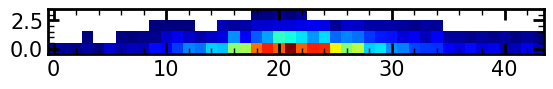

float32


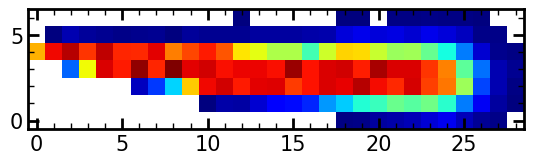

float32


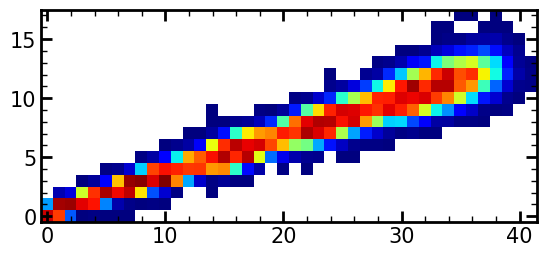

float32


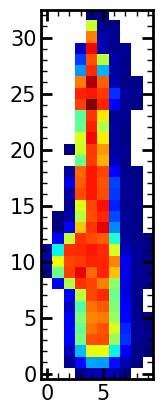

float32


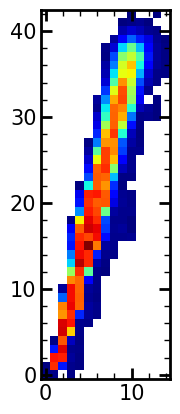

float32


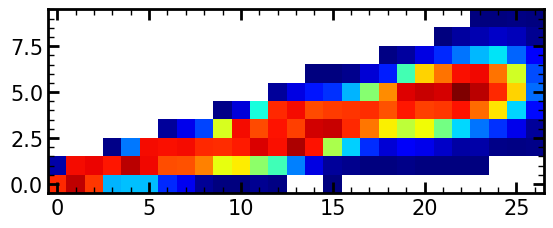

float32


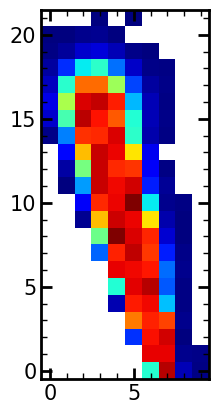

float32


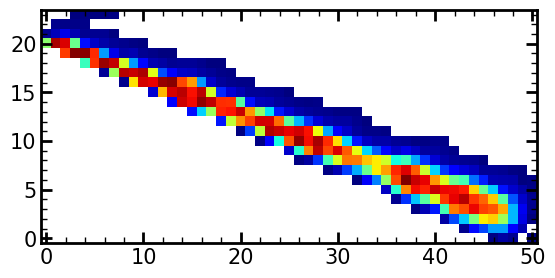

float32


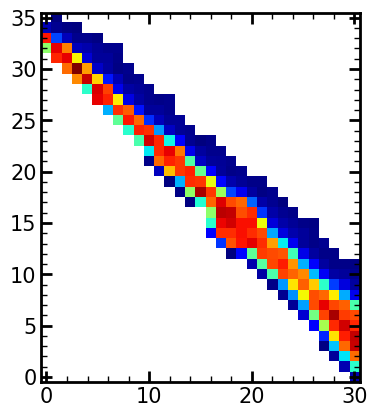

float32


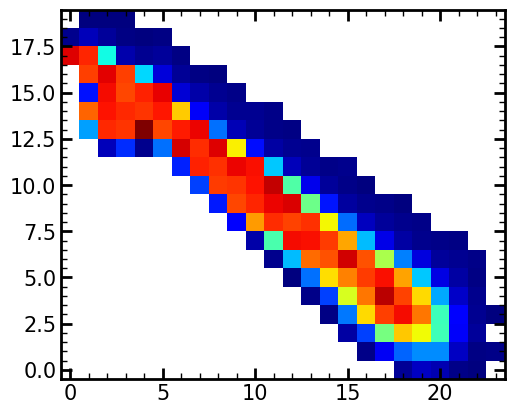

float32


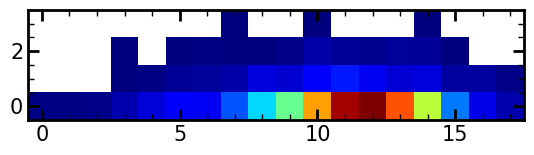

float32


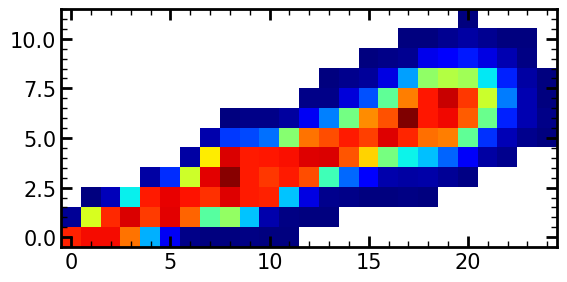

float32


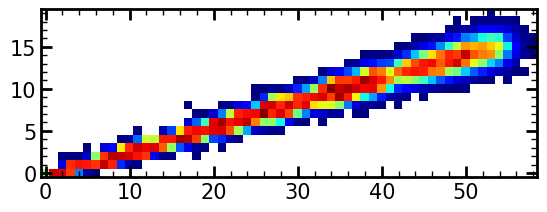

float32


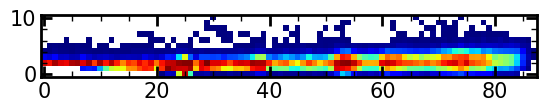

float32


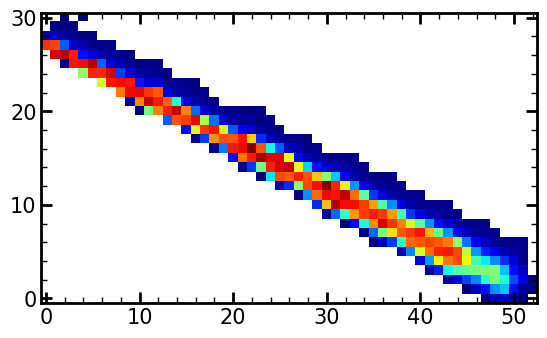

float32


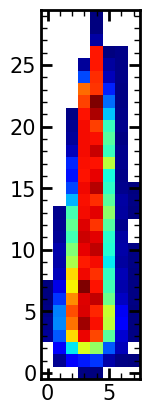

float32


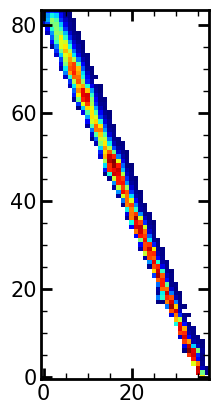

float32


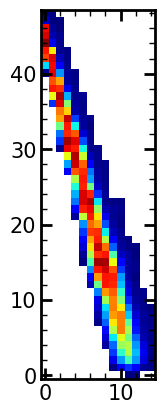

float32


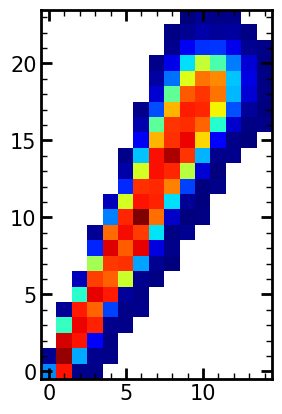

float32


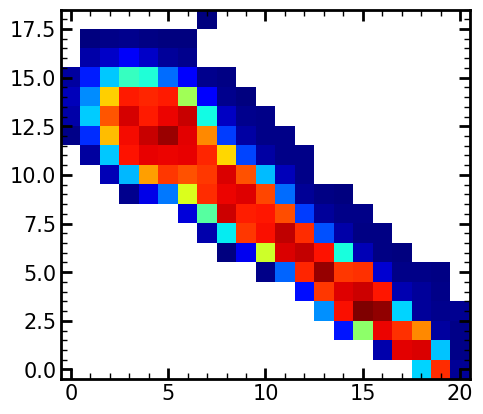

float32


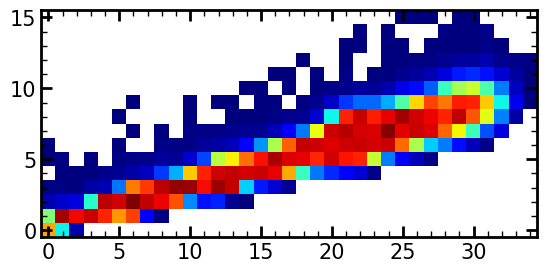

float32


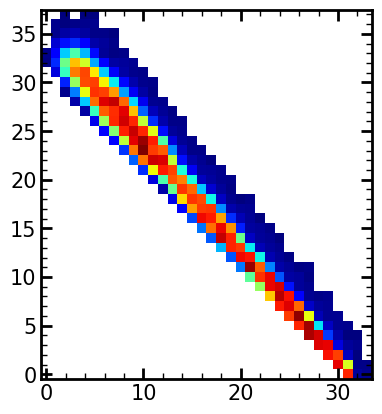

float32


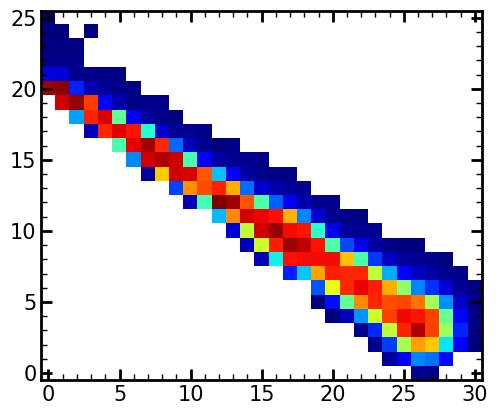

float32


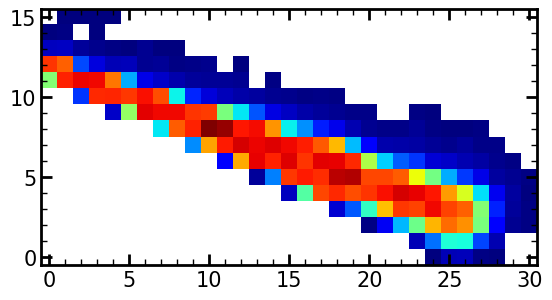

float32


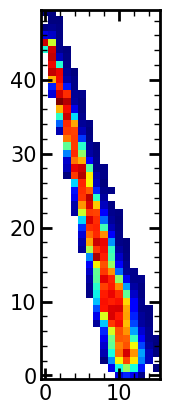

float32


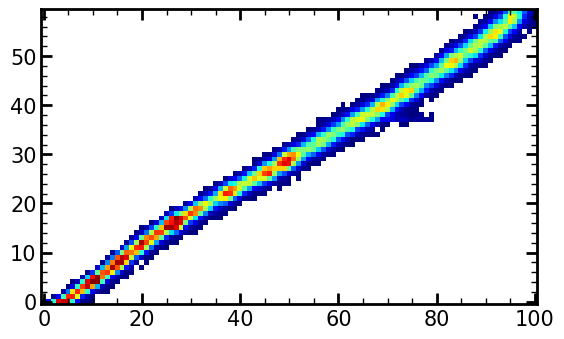

float32


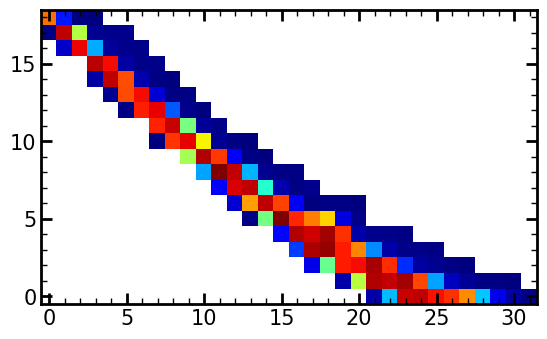

float32


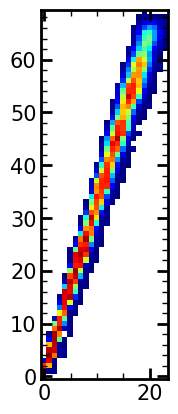

float32


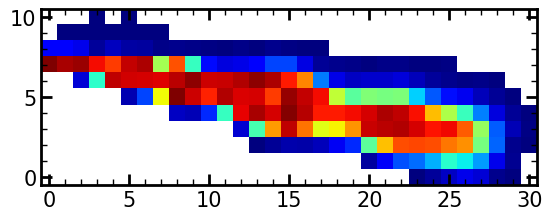

float32


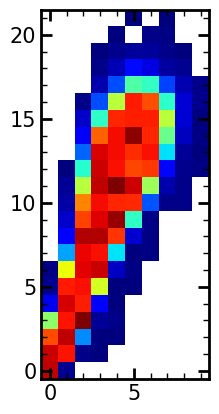

In [ ]:
label = 1
extension = 2

CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
# CCD_arrayOfficial = (1,2,5,6,7,9,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)

dict_extension  = data_histogram_all[f'extension_{extension}']['muons']

len_muons = len(dict_extension["image"])

print(f"Total of muons in the extension {extension}: {len_muons}")
# for element in range(0, len_muons):
for element in range(0, 30):
    muon_cluster = dict_extension["image"][element]
    print(muon_cluster.dtype)
    plt.imshow(muon_cluster, cmap="jet")
    plt.show()

### Pixel Charge distribution

Total of muons in the extension 1: 3495


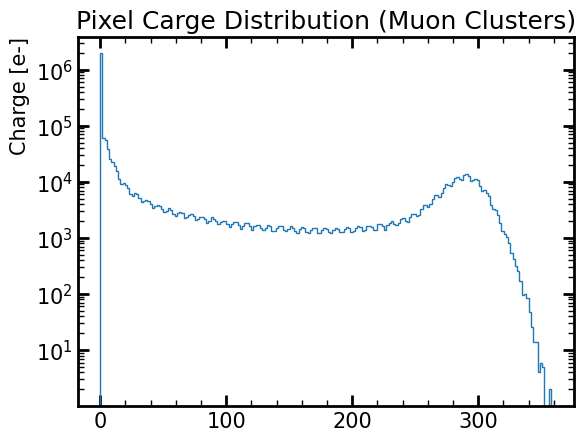

In [6]:
label = 1
extension = 1

CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
# CCD_arrayOfficial = (1,2,5,6,7,9,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)

dict_extension  = data_histogram_all[f'extension_{extension}']['muons']

len_muons = len(dict_extension["image"])
list_charge = []
print(f"Total of muons in the extension {extension}: {len_muons}")
for element in range(0, len_muons):
# for element in range(0, 3):
    muon_cluster = dict_extension["image"][element]
    for charge in muon_cluster.flatten():
        list_charge.append(charge)

plt.hist(list_charge, bins=200, histtype="step")
plt.title("Pixel Carge Distribution (Muon Clusters)")
plt.ylabel("Charge [e-]")
plt.yscale("log")
plt.show()

In [7]:
x_max = 430
y_max = 500
border = 10


combined_data = np.array(list_charge)
# print("Shape of combined data:", combined_data.shape)

Bins = 400
Bins_fit = Bins
# Range_fit = [-100, 400]

range_peak_init = 5
range_peak_final = 25

theo_peak = 320
diff = 0.7
true_peak = theo_peak - diff

data = combined_data.flatten()
print(len(data))
h3=TH1F("histogram", f"Active Area Charge Distribution (Ext {extension})",Bins_fit, range_peak_init-2, range_peak_final+2)
# h3.AddDirectory(False)

c1=TCanvas()
c1.SetLogy()
c1.SetGrid()
h3.SetStats(0)
h3.GetXaxis().SetTitle("Charge [e-]")
h3.Draw()

# leg = TLegend(0.5, 0.7, 0.9, 0.9)
# leg.AddEntry(fgaus, "Ajustes gaussianos", "L")
# leg.Draw()

dict_peaks = {"#Peak": [], "Mean": [], "Mean_err": [], "Sigma": [],  "Sigma_err": [], "Chi2": [], "NDF":[], "Prob":[]}
for pixel_value in data.flatten():
    # if not np.ma.is_masked(pixel_value):
    h3.Fill(pixel_value)
    #print(pixel_value)
    
saved_lines = []
# for peak in range(0, peak):
for peak in range(range_peak_init, range_peak_final+1):
    val_ref = peak

    value_fit = [0.3, 0.3]
    if peak >= 16:
        value_fit = [0.28, 0.28]

    if peak >= 40:
        value_fit = [0.37, 0.37]
        # L_option = "LRNQ"
        L_option = "RNQ"

    Range_fit_1 = [val_ref - value_fit[0], val_ref + value_fit[1]]
    fgaus = TF1("gaus1","gaus", Range_fit_1[0], Range_fit_1[1],3) # TF1("nombre", "funcion escrita como en root", min, max, #parametros)
    fgaus.SetParameters(10, true_peak, 1) # Establecer parametros iniciales del fit, de manera visual es posible determinarlos como una primera aproximacion

    if peak >= 50:
        h3.Fit(fgaus, L_option)

    else:
        h3.Fit(fgaus, "RNQ")
        
    fgaus.Draw("same")

    high = fgaus.GetParameters()[0]
    en_scape = peak
    # print(en_scape)
    line1 = TLine(en_scape, 0, en_scape, high)
    line1.SetLineColor(1)
    line1.SetLineWidth(1)
    line1.Draw("same")
    saved_lines.append(line1)

    mean = fgaus.GetParameters()[1]
    sigma = fgaus.GetParameters()[2]

    mean_err = fgaus.GetParError(1)
    sig_err = fgaus.GetParError(1)

    chi2 = fgaus.GetChisquare()
    ndf = fgaus.GetNDF()
    prob = fgaus.GetProb()

    dict_peaks["#Peak"].append(peak)
    dict_peaks["Mean"].append(mean)
    dict_peaks["Mean_err"].append(mean_err)
    dict_peaks["Sigma"].append(sigma)
    dict_peaks["Sigma_err"].append(sig_err)
    dict_peaks["Chi2"].append(chi2)
    dict_peaks["NDF"].append(ndf)
    dict_peaks["Prob"].append(prob)

    # c1.Draw()

leg = TLegend(0.6,0.75,0.9,0.9)
# leg.AddEntry(h3, "Data", "PL")
# leg.AddEntry(h3, r"cal = 196.881 \pm 7.802 ADU/e")
leg.AddEntry(fgaus, f"Gauss Fit", "L")
leg.AddEntry(line1, f"Expected Value", "L")
leg.Draw()

c1.Draw()

display(pd.DataFrame(dict_peaks))

peak_0 = dict_peaks["Mean"][0]
# print(peak_0)
list_gains = []
list_err_gains = []

for peak in range(1, len(dict_peaks["#Peak"])):
    # print(peak)
    # print(dict_peaks["Mean"][peak])
    gain = (dict_peaks["Mean"][peak])/dict_peaks["#Peak"][peak]
    gain_err = (dict_peaks["Mean_err"][peak])/dict_peaks["#Peak"][peak]

    list_gains.append(gain)
    list_err_gains.append(np.abs(gain_err))
    # print(f"Gain_0{dict_peaks['#Peak'][peak]}: {round(gain, 3)} +- {round(gain_err, 3)} e-")
print(f"Gain_0to{int(dict_peaks['#Peak'][peak])}: {round(gain, 5)} e-")


/tmp/ipykernel_5285/3127515129.py:6: UserWarning: Warning: converting a masked element to nan.
  combined_data = np.array(list_charge)


2795064


,#Peak,Mean,Mean_err,Sigma,Sigma_err,Chi2,NDF,Prob
0,5,5.014690,0.001444,0.174380,0.001444,4.745352,7,0.691006
1,6,6.022788,0.001482,0.172689,0.001482,8.610638,7,0.281832
2,7,7.021502,0.001613,0.175219,0.001613,2.791335,7,0.903611
3,8,8.024870,0.001820,0.172970,0.001820,5.230930,7,0.631805
4,9,9.027896,0.001904,0.173097,0.001904,11.650913,7,0.112639
5,10,10.028304,0.002019,0.173518,0.002019,5.530173,7,0.595547
6,11,11.030820,0.002295,0.170507,0.002295,6.779475,7,0.452197
7,12,12.035717,0.002447,0.175617,0.002447,8.719030,7,0.273463
8,13,13.037406,0.002486,0.173870,0.002486,8.377234,7,0.300507
9,14,14.035367,0.002863,0.172843,0.002863,9.310405,7,0.231132


Gain_0to25: 1.00213 e-


In [8]:
# combined_data = np.array(list_charge)
# print("Shape of combined data:", combined_data.shape)


range_peak_init = 10
range_peak_final = 100
Bins = 300
Bins_fit = Bins

data = combined_data.flatten()
h3=TH1F("histogram", f"Active Area Charge Distribution (Ext {extension})",Bins_fit, range_peak_init-2, range_peak_final+4)
# h3.AddDirectory(False)

c1=TCanvas()
c1.SetLogy()
c1.SetGrid()
h3.SetStats(0)
h3.GetXaxis().SetTitle("Charge [e-]")
h3.Draw()

# leg = TLegend(0.5, 0.7, 0.9, 0.9)
# leg.AddEntry(fgaus, "Ajustes gaussianos", "L")
# leg.Draw()

dict_peaks = {"#Peak": [], "Mean": [], "Mean_err": [], "Sigma": [],  "Sigma_err": [], "Chi2": [], "NDF":[], "Prob":[]}
for pixel_value in data.flatten():
    # if not np.ma.is_masked(pixel_value):
    h3.Fill(pixel_value)
    #print(pixel_value)
    
saved_lines = []
# for peak in range(0, peak):
for peak in range(range_peak_init, range_peak_final+1):
    diff = -0.2
    val_ref = peak + diff

    ## For extension 1 ##
    # value_fit = [0.22, 0.5] # range 5-20 diff 0.0
    # value_fit = [0.22, 0.5] # range 20-40 diff 0.02
    # value_fit = [0.22, 0.4] # range 40-60 diff 0.03
    # value_fit = [0.22, 0.4] # range 60-80 diff -0.1
    # value_fit = [0.22, 0.4] # range 80-100 diff -0.2
    # value_fit = [0.22, 0.5] # until 120 diff -0.25
    # value_fit = [0.22, 0.5] # until 141 diff -0.35
    # value_fit = [0.22, 0.5] # until 161 diff -0.45
    # value_fit = [0.22, 0.5] # until 181 diff -0.5
    # value_fit = [0.22, 0.5] # until 201 diff -0.6
    # value_fit = [0.22, 0.5] # until 221 diff -0.68
    # value_fit = [0.22, 0.5] # until 246 diff -0.8
    # value_fit = [0.22, 0.5] # until 266 diff -0.83
    # value_fit = [0.22, 0.5] # until 286 diff -0.9
    # value_fit = [0.22, 0.5] # until 301 diff -0.85
    # value_fit = [0.22, 0.5] # until 316 diff -0.8
    # value_fit = [0.22, 0.5] # until 330 diff -0.75

    ## For extension 2 ##
    # value_fit = [0.22, 0.5] # range 5-25 diff 0.0
    # value_fit = [0.22, 0.5] # range 26-46 diff 0.0
    # value_fit = [0.22, 0.5] # range 46-66 diff 0.0
    # value_fit = [0.22, 0.5] # range 66-86 diff 0.0
    # value_fit = [0.22, 0.5] # range 86-106 diff 0.0
    # value_fit = [0.22, 0.5] # range 106-126 diff 0.1
    # value_fit = [0.22, 0.5] # range 126-140 diff 0.2
    # value_fit = [0.22, 0.5] # until 140 diff 0.15 
    # value_fit = [0.3, 0.4] # until 160 diff 0.3
    # value_fit = [0.3, 0.4] # until 176 diff 0.6
    # value_fit = [0.3, 0.4] # until 189 diff 0.75
    # value_fit = [0.3, 0.4] # until 200 diff 0.95
    # value_fit = [0.3, 0.4] # until 217 diff 1.2
    # value_fit = [0.3, 0.4] # until 230 diff 1.5
    # value_fit = [0.25, 0.35] # until 240 diff 1.65
    # value_fit = [0.25, 0.35] # until 255 diff 1.8
    # value_fit = [0.25, 0.35] # until 270 diff 2.0
    # value_fit = [0.25, 0.35] # until 290 diff 2.1
    # value_fit = [0.25, 0.35] # until 315 diff 2.2
    # value_fit = [0.25, 0.35] # until 327 diff 2.3 
    # value_fit = [0.25, 0.35] # until 338 diff 2.25
    # value_fit = [0.25, 0.35] # until 360 diff 2.1
    # value_fit = [0.25, 0.35] # until 379 diff 2.0
    # value_fit = [0.25, 0.35] # until 395 diff 1.9
    # value_fit = [0.25, 0.35] # until 420 diff 1.65
    # value_fit = [0.25, 0.35] # until 435 diff 1.50
    # value_fit = [0.25, 0.35] # until 445 diff 1.3
    # value_fit = [0.25, 0.35] # until 456 diff 1.2
    # value_fit = [0.25, 0.35] # until 470 diff  0.9
    # value_fit = [0.25, 0.35] # until 480 diff 0.8
    # value_fit = [0.25, 0.35] # until 489 diff 0.65
    # value_fit = [0.25, 0.35] # until 500 diff 0.5
    # value_fit = [0.25, 0.35] # until 511 diff 0.35
    # value_fit = [0.25, 0.35] # until 521 diff 0.2
    # value_fit = [0.25, 0.35] # until 531 diff 0.0
    # value_fit = [0.25, 0.35] # until 542 diff -0.2
    # value_fit = [0.25, 0.35] # until 552 diff -0.3
    # value_fit = [0.25, 0.35] # until 562 diff -0.5
    # value_fit = [0.25, 0.35] # until 586 diff -0.9
    # value_fit = [0.25, 0.35] # until 586 diff -1.2
    # L_option = "LRNQ"
    L_option = "RNQ"

    Range_fit_1 = [val_ref - value_fit[0], val_ref + value_fit[1]]
    fgaus = TF1("gaus1","gaus", Range_fit_1[0], Range_fit_1[1],3) # TF1("nombre", "funcion escrita como en root", min, max, #parametros)
    fgaus.SetParameters(10, val_ref, 1) # Establecer parametros iniciales del fit, de manera visual es posible determinarlos como una primera aproximacion

    if peak >= 50:
        h3.Fit(fgaus, L_option)

    else:
        h3.Fit(fgaus, "RNQ")
        
    fgaus.Draw("same")

    high = fgaus.GetParameters()[0]
    en_scape = peak
    # print(en_scape)
    line1 = TLine(en_scape, 0, en_scape, high)
    line1.SetLineColor(1)
    line1.SetLineWidth(2)
    line1.Draw("same")
    saved_lines.append(line1)

    mean = fgaus.GetParameters()[1]
    sigma = fgaus.GetParameters()[2]

    mean_err = fgaus.GetParError(1)
    sig_err = fgaus.GetParError(1)

    chi2 = fgaus.GetChisquare()
    ndf = fgaus.GetNDF()
    prob = fgaus.GetProb()

    dict_peaks["#Peak"].append(peak)
    dict_peaks["Mean"].append(mean)
    dict_peaks["Mean_err"].append(mean_err)
    dict_peaks["Sigma"].append(sigma)
    dict_peaks["Sigma_err"].append(sig_err)
    dict_peaks["Chi2"].append(chi2)
    dict_peaks["NDF"].append(ndf)
    dict_peaks["Prob"].append(prob)

    # c1.Draw()

leg = TLegend(0.6,0.75,0.9,0.9)
# leg.AddEntry(h3, "Data", "PL")
# leg.AddEntry(h3, r"cal = 196.881 \pm 7.802 ADU/e")
leg.AddEntry(fgaus, f"Gauss Fit", "L")
leg.AddEntry(line1, f"Expected Value", "L")
leg.Draw()

c1.Draw()

display(pd.DataFrame(dict_peaks))

peak_0 = dict_peaks["Mean"][0]
# print(peak_0)
list_gains = []
list_err_gains = []

for peak in range(1, len(dict_peaks["#Peak"])):
    # print(peak)
    # print(dict_peaks["Mean"][peak])
    gain = (dict_peaks["Mean"][peak])/dict_peaks["#Peak"][peak]
    gain_err = (dict_peaks["Mean_err"][peak])/dict_peaks["#Peak"][peak]

    list_gains.append(gain)
    list_err_gains.append(np.abs(gain_err))
    # print(f"Gain_0{dict_peaks['#Peak'][peak]}: {round(gain, 3)} +- {round(gain_err, 3)} e-")
print(f"Gain_0to{int(dict_peaks['#Peak'][peak])}: {round(gain, 5)} e-")


,#Peak,Mean,Mean_err,Sigma,Sigma_err,Chi2,NDF,Prob
0,10,9.985123,0.016433,0.153472,0.016433,2.256845e-08,0,0.0
1,11,10.959734,0.019702,0.142490,0.019702,2.162595e-06,0,0.0
2,12,11.926689,0.022304,0.134306,0.022304,8.816452e-09,0,0.0
3,13,12.908762,0.285746,0.135814,0.285746,1.739904e-07,0,0.0
4,14,13.839738,0.022379,0.113034,0.022379,9.364893e-06,0,0.0
...,...,...,...,...,...,...,...,...
86,96,95.764613,0.681502,0.137341,0.681502,1.467877e-06,0,0.0
87,97,96.623687,0.194836,0.246850,0.194836,8.847011e-08,0,0.0
88,98,97.884431,0.131156,0.168472,0.131156,1.601445e-08,0,0.0
89,99,98.859737,0.106635,0.173654,0.106635,1.493818e-07,0,0.0


Gain_0to100: 0.99853 e-


Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).


In [9]:
Bins = 100
Bins_fit = Bins
# Range_fit = [-100, 400]

max_value = max(data)
print(data)
if extension == 1:
    max_value = 350
    
h3=TH1F("histogram", f"Active Area Charge Distribution (Ext {extension})",Bins_fit, -2, max_value+10)
# h3.AddDirectory(False)
for pixel_value in data.flatten():
    # if not np.ma.is_masked(pixel_value):
    h3.Fill(pixel_value)
    #print(pixel_value)

c1=TCanvas()
c1.SetLogy()
c1.SetGrid()
h3.SetStats(0)
h3.GetXaxis().SetTitle("Charge [e-]")
h3.Draw()
c1.Draw()

# max_bin = h3.GetMaximumBin();
max_bin = h3.GetMaximumBin();

if extension == 1:
    interface1 = 60
    interface2 = 300

if extension == 2:
    interface1 = 140
    interface2 = 531

range_area1 = [max_bin+4,interface1]
range_area2 = [range_area1[1]+4,interface2]
range_area3 = [range_area2[1]+3,max_value]

first_bin1 = h3.GetXaxis().FindBin(range_area1[0])
last_bin1 =  h3.GetXaxis().FindBin(range_area1[1])

first_bin2 = h3.GetXaxis().FindBin(range_area2[0])
last_bin2 =  h3.GetXaxis().FindBin(range_area2[1])

first_bin3 = h3.GetXaxis().FindBin(range_area3[0])
last_bin3 =  h3.GetXaxis().FindBin(range_area3[1])
# print(f"Selected range 1: {first_bin, last_bin}")

area1 = h3.Integral(first_bin1, last_bin1)
area2 = h3.Integral(first_bin2, last_bin2)
area3 = h3.Integral(first_bin3, last_bin3)

shaded1 = h3.Clone("shaded1")
shaded2 = h3.Clone("shaded2")
shaded3 = h3.Clone("shaded3")

shaded1.GetXaxis().SetRangeUser(range_area1[0], range_area1[1])
shaded2.GetXaxis().SetRangeUser(range_area2[0], range_area2[1])
shaded3.GetXaxis().SetRangeUser(range_area3[0], range_area3[1])

# Style and draw overlay
shaded1.SetFillColor(3) 
shaded1.SetFillStyle(3001)  # Semi-transparent style
shaded1.Draw("HIST SAME")

shaded2.SetFillColor(94)  
shaded2.SetFillStyle(3001)  # Semi-transparent style
shaded2.Draw("HIST SAME")

shaded3.SetFillColor(2)  
shaded3.SetFillStyle(3001)  # Semi-transparent style
shaded3.Draw("HIST SAME")

# high = fgaus.GetParameters()[0]
# en_scape = theo_peak
# line1 = TLine(en_scape, 0, en_scape, high)
# line1.SetLineColor(1)
# line1.SetLineWidth(2)
# line1.Draw()
total_Area = area1 + area2+ area3
percet1 = round((area1/total_Area)*100,1)
percet2 = round((area2/total_Area)*100,1)
percet3 = round((area3/total_Area)*100,1)
print(f"Total Area: {total_Area}")
print(f"Area OKAY: {area1} ({percet1}%)")
print(f"Area BAD: {area2} ({percet2}%)")
print(f"Area WARNING: {area3} ({percet3}%)")


leg = TLegend(0.55,0.75,0.9,0.9)
# leg.AddEntry(h3, "Data", "PL")
# leg.AddEntry(h3, r"cal = 196.881 \pm 7.802 ADU/e")
leg.AddEntry(shaded1, f"Functional Area (Gain = 1)", "HF")
leg.AddEntry(shaded2, f"More Charge (Gain > 1)", "HF")
leg.AddEntry(shaded3, f"Less Charge (Gain < 1)", "HF")
# leg.AddEntry(line1, f"Theoretical Value: {en_scape}", "L")
leg.Draw()


[nan nan nan ... nan nan nan]
Total Area: 722388.0
Area OKAY: 262255.0 (36.3%)
Area BAD: 410703.0 (56.9%)
Area WARNING: 49430.0 (6.8%)


Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).


In [10]:
label = 1
extension = 1

CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
# CCD_arrayOfficial = (1,2,5,6,7,9,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)

dict_extension  = data_histogram_all[f'extension_{extension}']['muons']

len_muons = len(dict_extension["image"])
list_charge = []
print(f"Total of muons in the extension {extension}: {len_muons}")
for element in range(0, len_muons):
# for element in range(0, 3):
    muon_cluster = dict_extension["image"][element]
    for charge in muon_cluster.flatten():
        list_charge.append(charge)

data = np.array(list_charge).flatten()
# === Extension 1 === ##
if extension == 1:
    list_range_fit = [[0.22, 0.5], [0.22, 0.5], [0.22, 0.4], [0.22, 0.4], [0.22, 0.4], 
                    [0.22, 0.5], [0.22, 0.5], [0.22, 0.5], [0.22, 0.5], [0.22, 0.5],
                    [0.22, 0.5], [0.22, 0.5], [0.22, 0.5], [0.22, 0.5], [0.22, 0.5],
                    [0.22, 0.5], [0.22, 0.5]]
    list_diff = [0.0, 0.02, 0.03, -0.1, -0.2,
                -0.25, -0.35, -0.45, -0.5, -0.6,
                -0.68, -0.8, -0.83, -0.9, -0.85,
                -0.8, -0.75,]
    list_range_hist = [[5, 20], [20, 40], [40, 60], [60, 80], [80, 100], 
                    [100,120], [121, 141], [141, 161], [161, 181] ,[181, 201], 
                    [201, 221], [221, 246], [246, 266], [266, 286], [286, 301], 
                    [301, 316], [316, 330]]
# =================== ##

if extension == 2:
# === Extension 2 === ##
    list_range_fit = [[0.22, 0.5], [0.22, 0.5], [0.22, 0.5], [0.22, 0.5], [0.22, 0.5], [0.22, 0.5],
                    [0.22, 0.5], [0.3, 0.4], [0.3, 0.4], [0.3, 0.4], [0.3, 0.4], [0.3, 0.4], [0.3, 0.4],
                    [0.25, 0.35], [0.25, 0.35], [0.25, 0.35], [0.25, 0.35], [0.25, 0.35], [0.25, 0.35],
                    [0.25, 0.35], [0.25, 0.35], [0.25, 0.35], [0.25, 0.35], [0.25, 0.35], [0.25, 0.35],
                    [0.25, 0.35], [0.25, 0.35], [0.25, 0.35], [0.25, 0.35], [0.25, 0.35], [0.25, 0.35],
                    [0.25, 0.35], [0.25, 0.35], [0.25, 0.35], [0.25, 0.35], [0.25, 0.35], [0.25, 0.35],
                    [0.25, 0.35], [0.25, 0.35]]

    list_diff = [0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.15, 0.3, 0.6, 0.75, 0.95, 
                1.2, 1.5, 1.65, 1.8, 2.0, 2.1, 2.2, 2.3, 2.25, 2.1, 2.0, 1.9, 
                1.65, 1.50, 1.3, 1.2, 0.9, 0.8, 0.65, 0.5, 0.35, 0.2, 0.0, 
                -0.2, -0.3, -0.5, -0.9, -1.2]

    list_range_hist = [[5, 25], [26, 46], [46, 66], [66, 86], [86, 106], [106, 126],
                    [126, 140], [141, 160], [161, 176], [177, 189], [190, 200], [201, 217], [218, 230], [230, 240], [240, 255], [255, 270], [271, 290],
                    [291, 315], [316, 327], [328, 338], [339, 360], [361, 379], [380, 395], [396, 420], [421, 435], [436, 445], [446, 456], [457, 470],
                    [471, 480], [480, 489], [490, 500], [501, 511], [511, 521], [521, 531], [532, 542], [542, 552], [552, 562], [562, 586], [586, 600]]
# =================== #

dict_peaks = {"#Peak": [], "Mean": [], "Mean_err": [], "Sigma": [],  "Sigma_err": [], "Chi2": [], "NDF":[], "Prob":[]}
for index in range(0, len(list_range_fit)):
    # print(list_range_fit[index], list_diff[index])

    range_peak = list_range_hist[index]
    fit_range = list_range_fit[index]
    diff = list_diff[index]

    print(f"Range peaks: [{range_peak[0], range_peak[1]}]")
    print(f"Fit Range:  [{fit_range[0], fit_range[1]}]")
    print(f"Diff: {diff}")

    Bins = 300
    Bins_fit = Bins

    # data = combined_data.flatten()
    h3=TH1F("histogram", f"Active Area Charge Distribution (Ext {extension})",Bins_fit, range_peak[0]-2, range_peak[1]+4)
    for pixel_value in data.flatten():
        # if not np.ma.is_masked(pixel_value):
        h3.Fill(pixel_value)
        #print(pixel_value)

    # for peak in range(0, peak):
    for peak in range(range_peak[0], range_peak[1]+1):
        val_ref = peak + diff
        # L_option = "LRNQ"
        L_option = "RNQ"

        Range_fit = [val_ref - fit_range[0], val_ref + fit_range[1]]
        fgaus = TF1("gaus1","gaus", Range_fit[0], Range_fit[1],3) # TF1("nombre", "funcion escrita como en root", min, max, #parametros)
        fgaus.SetParameters(10, val_ref, 1) # Establecer parametros iniciales del fit, de manera visual es posible determinarlos como una primera aproximacion

        h3.Fit(fgaus, L_option)
        mean = fgaus.GetParameters()[1]
        sigma = fgaus.GetParameters()[2]

        mean_err = fgaus.GetParError(1)
        sig_err = fgaus.GetParError(1)

        chi2 = fgaus.GetChisquare()
        ndf = fgaus.GetNDF()
        prob = fgaus.GetProb()

        dict_peaks["#Peak"].append(peak)
        dict_peaks["Mean"].append(mean)
        dict_peaks["Mean_err"].append(mean_err)
        dict_peaks["Sigma"].append(sigma)
        dict_peaks["Sigma_err"].append(sig_err)
        dict_peaks["Chi2"].append(chi2)
        dict_peaks["NDF"].append(ndf)
        dict_peaks["Prob"].append(prob)



Total of muons in the extension 1: 3495


/tmp/ipykernel_5285/4055573869.py:19: UserWarning: Warning: converting a masked element to nan.
  data = np.array(list_charge).flatten()


Range peaks: [(5, 20)]
Fit Range:  [(0.22, 0.5)]
Diff: 0.0
Range peaks: [(20, 40)]
Fit Range:  [(0.22, 0.5)]
Diff: 0.02
Range peaks: [(40, 60)]
Fit Range:  [(0.22, 0.4)]
Diff: 0.03
Range peaks: [(60, 80)]
Fit Range:  [(0.22, 0.4)]
Diff: -0.1
Range peaks: [(80, 100)]
Fit Range:  [(0.22, 0.4)]
Diff: -0.2
Range peaks: [(100, 120)]
Fit Range:  [(0.22, 0.5)]
Diff: -0.25
Range peaks: [(121, 141)]
Fit Range:  [(0.22, 0.5)]
Diff: -0.35
Range peaks: [(141, 161)]
Fit Range:  [(0.22, 0.5)]
Diff: -0.45
Range peaks: [(161, 181)]
Fit Range:  [(0.22, 0.5)]
Diff: -0.5
Range peaks: [(181, 201)]
Fit Range:  [(0.22, 0.5)]
Diff: -0.6
Range peaks: [(201, 221)]
Fit Range:  [(0.22, 0.5)]
Diff: -0.68
Range peaks: [(221, 246)]
Fit Range:  [(0.22, 0.5)]
Diff: -0.8
Range peaks: [(246, 266)]
Fit Range:  [(0.22, 0.5)]
Diff: -0.83
Range peaks: [(266, 286)]
Fit Range:  [(0.22, 0.5)]
Diff: -0.9
Range peaks: [(286, 301)]
Fit Range:  [(0.22, 0.5)]
Diff: -0.85
Range peaks: [(301, 316)]
Fit Range:  [(0.22, 0.5)]
Diff: -0

Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing exist

In [11]:
display(pd.DataFrame(dict_peaks))

,#Peak,Mean,Mean_err,Sigma,Sigma_err,Chi2,NDF,Prob
0,5,5.014414,0.001486,0.179945,0.001486,16.418525,8,0.036767
1,6,6.023639,0.001802,0.175158,0.001802,13.428179,7,0.062338
2,7,7.020416,0.001887,0.178150,0.001887,13.125418,7,0.069111
3,8,8.027705,0.001810,0.177807,0.001810,20.074197,8,0.010059
4,9,9.027434,0.002479,0.179493,0.002479,20.714499,7,0.004217
...,...,...,...,...,...,...,...,...
336,326,325.294065,0.014840,0.204168,0.014840,3.953782,8,0.861269
337,327,326.309813,0.013765,0.191623,0.013765,23.597076,8,0.002677
338,328,327.315283,0.014260,0.198128,0.014260,5.307556,8,0.724255
339,329,328.319878,0.014011,0.184522,0.014011,1.821557,8,0.986002


[ 1.39653729e-05 -6.22773189e-03  3.53288042e-01]


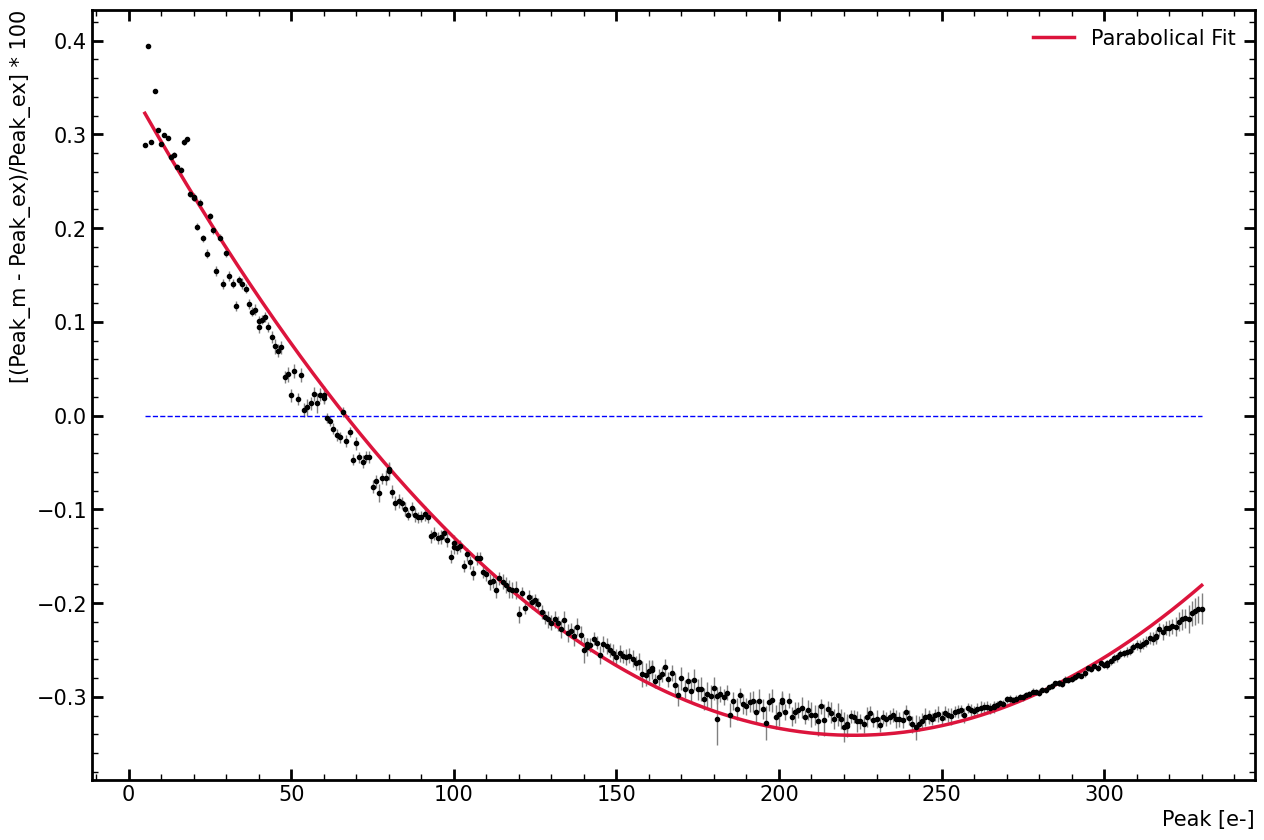

In [15]:
# display(pd.DataFrame(dict_peaks))
from scipy.optimize import curve_fit
from scipy.interpolate import UnivariateSpline
from scipy.special import erf

def skew_normal_plus_linear(x, A, xi, omega, alpha, m, b):
    # Skew normal component
    t = (x - xi) / omega
    skew_norm = A * np.exp(-t**2 / 2) * (1 + erf(alpha * t / np.sqrt(2)))
    # Linear component
    return skew_norm + m * x + b

def gaussian_plus_linear(x, A, x0, sigma, m, b):
    return A * np.exp(-(x - x0)**2 / (2 * sigma**2)) + m * x + b

def cubic_poly(x, c3, c2, c1, c0) :
    return c3*x**3 + c2*x**2 + c1*x + c0

def parabol(x, a, b, c):
    return a*x**2 + b*x + c

limit = 1
list_diff = []
list_peaks = []
list_err = []
for index in range(0, len(dict_peaks["#Peak"])):
    measured_peak = dict_peaks["Mean"][index]
    expected_peak = dict_peaks["#Peak"][index]
    err=dict_peaks["Mean_err"][index]

    diff = (measured_peak - expected_peak)/expected_peak
    # diff = (measured_peak - expected_peak)
    # if diff*100 < -0.25: # for extension 2
    #     print(f"Peak: {dict_peaks['#Peak'][index]}")
    #     print(f"Mean: {dict_peaks['Mean'][index]}")
    #     print(f"Chi2: {dict_peaks['Chi2'][index]}")
    #     print(f"NDF: {dict_peaks['NDF'][index]}")
    #     print(f"Prob: {dict_peaks['Prob'][index]} \n")
    #     continue

    # list_diff.append(np.abs(diff) * 100)
    list_diff.append(diff * 100)
    # list_diff.append(diff)
    list_peaks.append(dict_peaks['#Peak'][index])
    list_err.append(err)

# A (amp)=0.8, xi (loc)=260, omega (scale)=120, alpha (skew)=1.5
# m (slope) ~ -0.003, b (intercept) ~ 1.5
initial_guess_skew = [0.8, 260.0, 120.0, 1.5, -0.003, 1.5]
x_fit = np.linspace(min(list_peaks), max(list_peaks), 1000)

if extension == 1:
    popt_parabol, _ = curve_fit(parabol, list_peaks, list_diff, sigma=list_err, p0=[0.01,-0.1, -0.2])
    print(popt_parabol)
    y_fit = parabol(x_fit, *popt_parabol)

if extension == 2:
    popt_skew, pcov_skew = curve_fit(
        skew_normal_plus_linear, 
        list_peaks, 
        list_diff, 
        p0=initial_guess_skew
    )
    A_opt, xi_opt, omega_opt, alpha_opt, m_opt, b_opt = popt_skew
    print("--- FINAL MATHEMATICAL EXPRESSION ---")
    print(f"f(x) = {A_opt:.5f} * exp(-((x - {xi_opt:.2f}) / {omega_opt:.2f})**2 / 2) * "
        f"(1 + erf({alpha_opt:.4f} * (x - {xi_opt:.2f}) / ({np.sqrt(2)*omega_opt:.2f}))) "
        f"+ ({m_opt:.6f}) * x + {b_opt:.5f}")

    x_fit = np.linspace(min(list_peaks), max(list_peaks), 1000)
    y_fit_skew = skew_normal_plus_linear(x_fit, *popt_skew)

idx = np.argsort(list_peaks)
x_sorted = np.array(list_peaks)[idx]
y_sorted = np.array(list_diff)[idx]

spline = UnivariateSpline(x_sorted, y_sorted, s=0.05)
x_smooth = np.linspace(x_sorted.min(), x_sorted.max(), 1000)
y_smooth = spline(x_smooth)

fig, axs = plt.subplots(figsize = [15,10])
# axs.scatter(list_peaks, list_diff, marker = ".", color = "k", s=1)
axs.errorbar(x=list_peaks, y=list_diff, yerr=list_err, marker = ".", color = "k", mec="k", ecolor = "gray", linestyle='none')
axs.hlines(y=0, xmax=max(list_peaks), xmin=min(list_peaks), linestyles="--", colors="b")
if extension == 1:
    axs.plot(x_fit, y_fit, color='crimson', lw=2.5, label='Parabolical Fit')
if extension == 2:
    axs.plot(x_smooth, y_smooth, color='blue', lw=2, label='Univariate Spline') 
    axs.plot(x_fit, y_fit_skew, color='crimson', lw=2.5, label='Skew-Normal + Linear Fit')

axs.set_ylabel("[(Peak_m - Peak_ex)/Peak_ex] * 100")
axs.set_xlabel("Peak [e-]")
plt.legend()
plt.show()

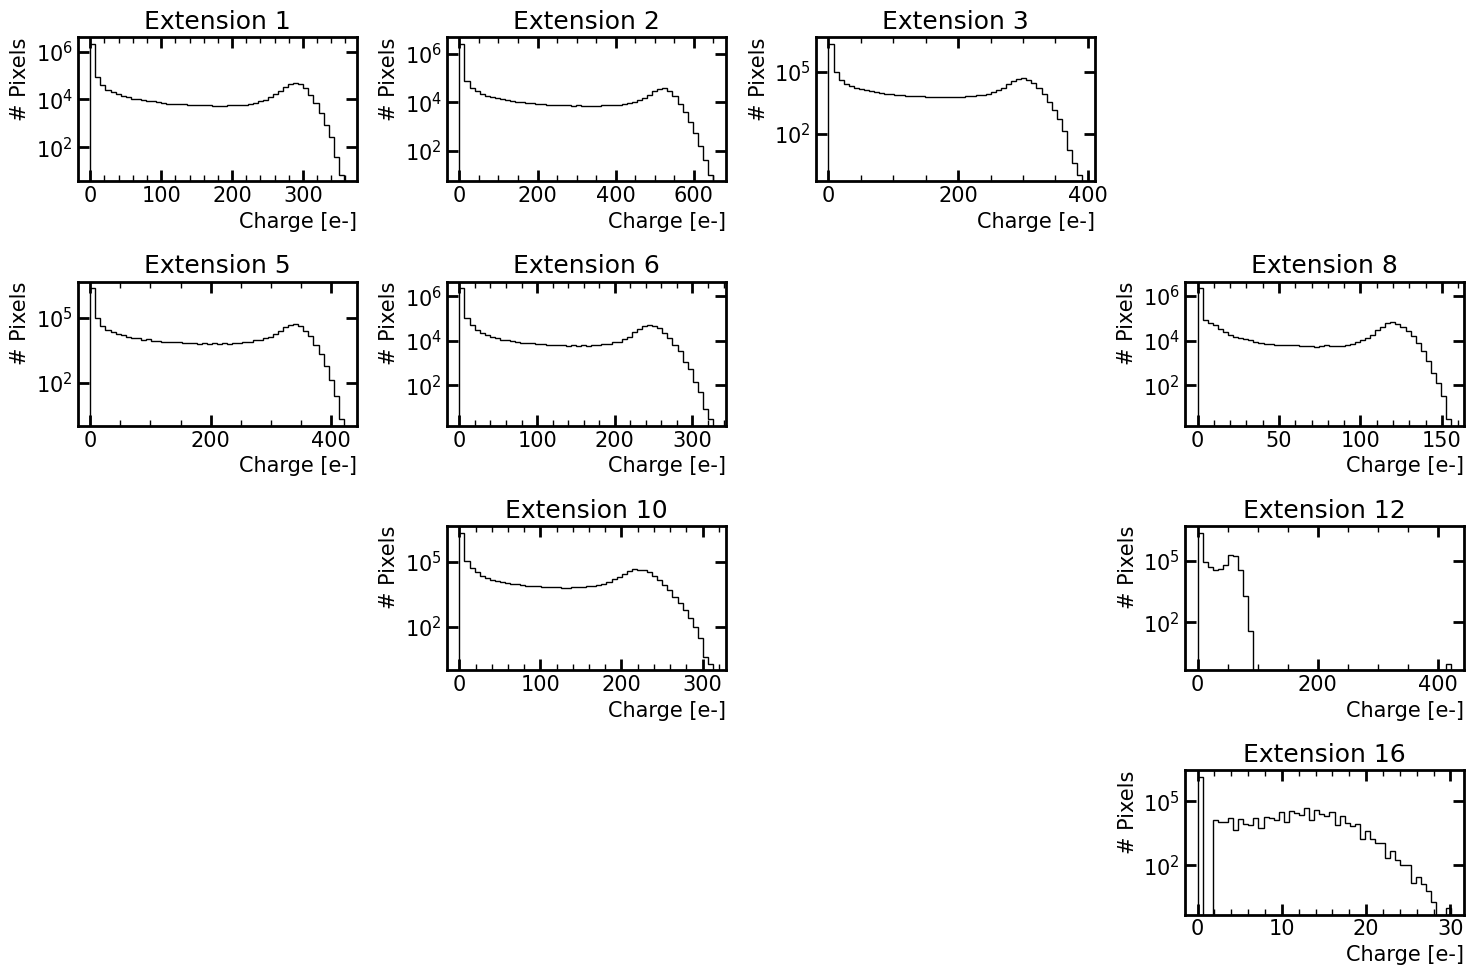

In [61]:
plot_range = (0, 350)
Bins = 50
plt.figure(figsize = [15,10])

for ext in CCD_array:
    if ext in CCD_bad:
        continue
    list_charge = []
    list_muon_cluster  = data_histogram_all[f'extension_{ext}']['muons']["image"]
    for element in list_muon_cluster:
        for charge in element.flatten():
            list_charge.append(charge)

    plt.subplot(4,4,ext)
    plt.hist(list_charge, bins = Bins, color = 'k',  histtype = 'step')#,range= (plot_range[0], plot_range[1]))
    plt.title('Extension '+str(ext))
    plt.ylabel('# Pixels')
    plt.xlabel('Charge [e-]')

    ## Escala Log
    plt.yscale('log')

# plt.title("Pixel Carge Distribution (Muon Clusters)")
plt.tight_layout()
plt.show()


### Mean charge

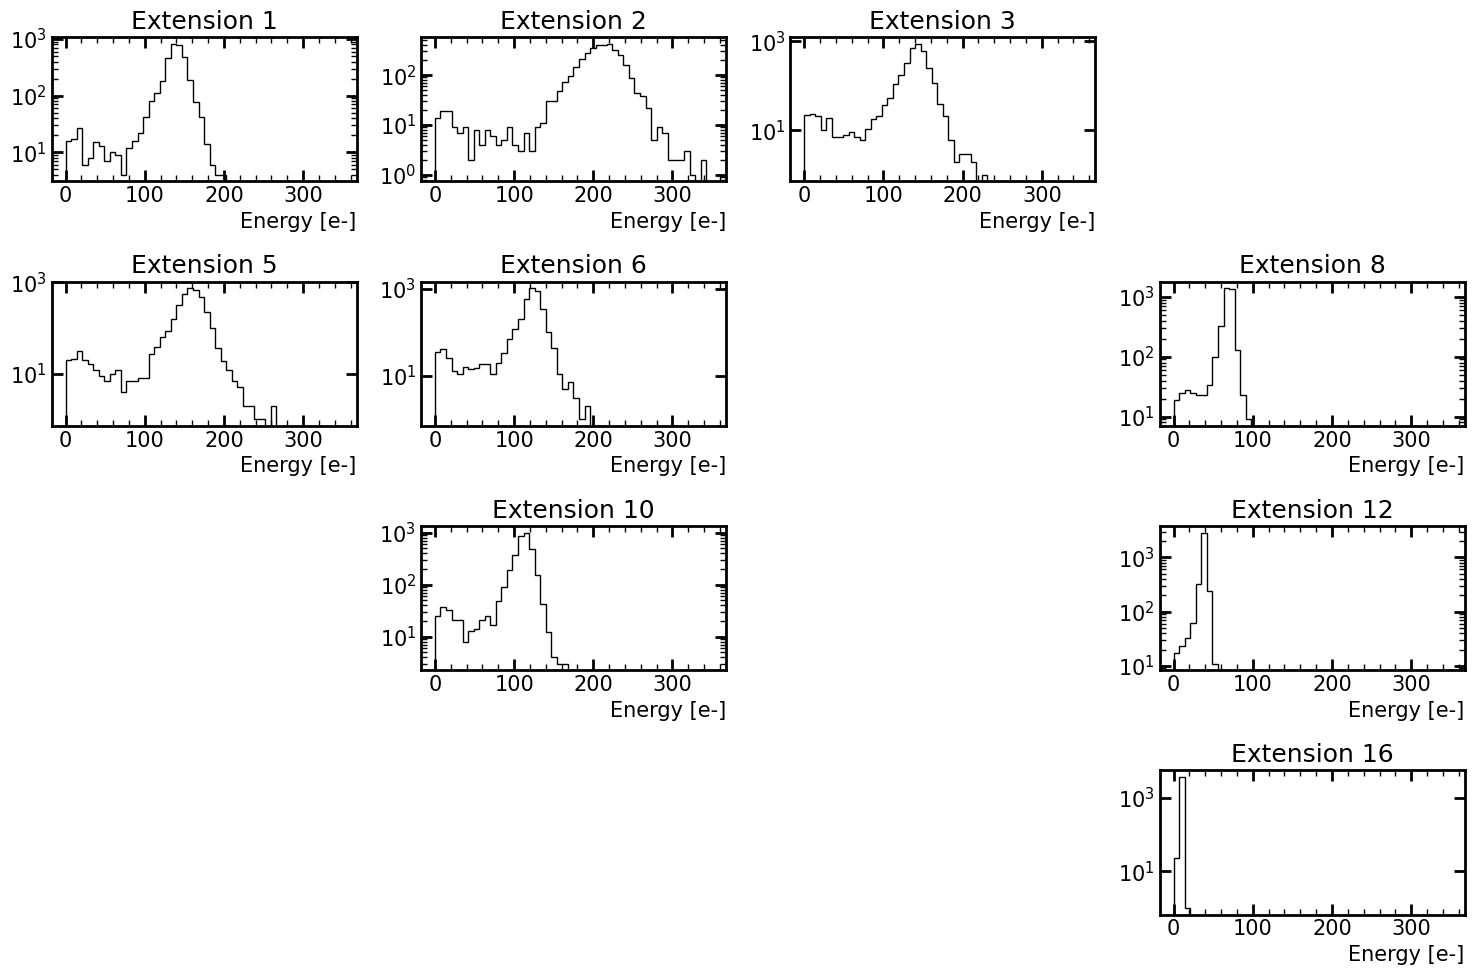

In [116]:
CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
# CCD_array = (1,2,5,6,7,9,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)

BINS = 50
plot_range = (0, 350)

plt.figure(figsize = [15,10])
for ext in CCD_array:
    if ext in CCD_bad:
        continue
    muon_meanCharge  = data_histogram_all[f'extension_{ext}']['muons']["mean_charge"]

    plt.subplot(4,4,ext)
    plt.hist(muon_meanCharge, bins = BINS, color = 'k',  histtype = 'step',range= (plot_range[0], plot_range[1]))
    plt.title('Extension '+str(ext))
    # axs.ylabel('Y_pix')
    plt.xlabel('Energy [e-]')

    ## Escala Log
    plt.yscale('log')

# plt.legend()

## EScala Normal
# axs.set_ylim(0,200)
# axs.set_xlim(0,190000)

plt.tight_layout()
plt.show()
    

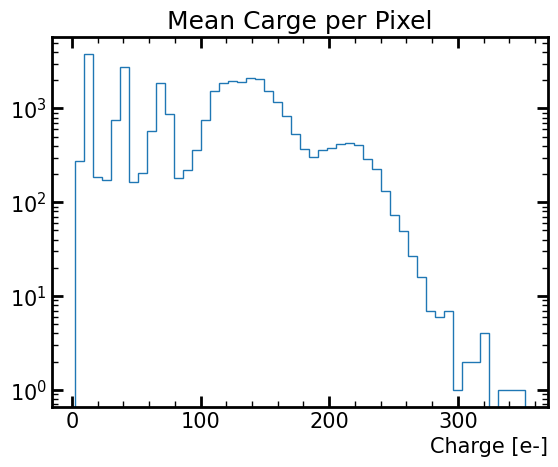

In [21]:
list_meanCharge_allExt = []
for extension in CCD_array:
    if extension in CCD_bad:
        continue
    muon_meanCharge  = data_histogram_all[f'extension_{extension}']['muons']["mean_charge"]
    for element in muon_meanCharge:
        list_meanCharge_allExt.append(element)

fig, axs = plt.subplots(1,1)
axs.hist(list_meanCharge_allExt, bins=50, histtype="step")
axs.set_xlabel("Charge [e-]")
axs.set_title("Mean Carge per Pixel")
axs.set_yscale("log")
plt.show()

### Charge Deposition

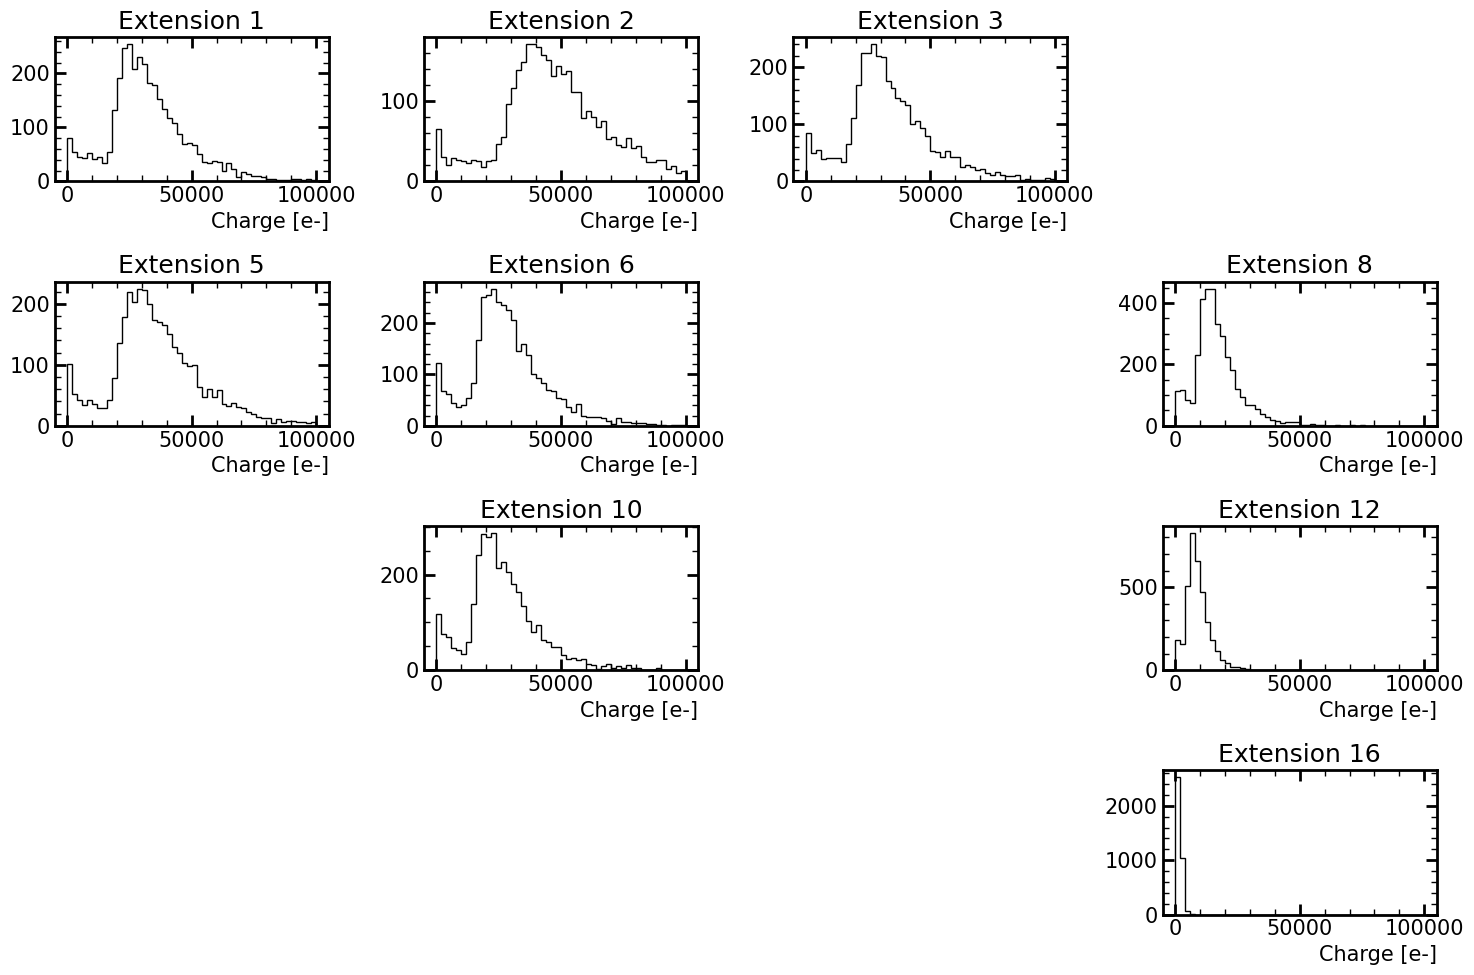

In [118]:
CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
# CCD_array = (1,2,5,6,7,9,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)

BINS = 50
plot_range = (0, 100000)

plt.figure(figsize = [15,10])
# plt.title("Charge Deposition Distribution (from Muon clusters)")
for ext in CCD_array:
    if ext in CCD_bad:
        continue
    muon_chargeDep  = data_histogram_all[f'extension_{ext}']['muons']["charge_muons"]

    plt.subplot(4,4,ext)
    plt.hist(muon_chargeDep, bins = BINS, color = 'k',  histtype = 'step',range= (plot_range[0], plot_range[1]))
    plt.title('Extension '+str(ext))
    # axs.ylabel('Y_pix')
    plt.xlabel('Charge [e-]')

    ## Escala Log
    # plt.yscale('log')

# plt.legend()

## EScala Normal
# axs.set_ylim(0,200)
# axs.set_xlim(0,190000)

plt.tight_layout()
plt.show()

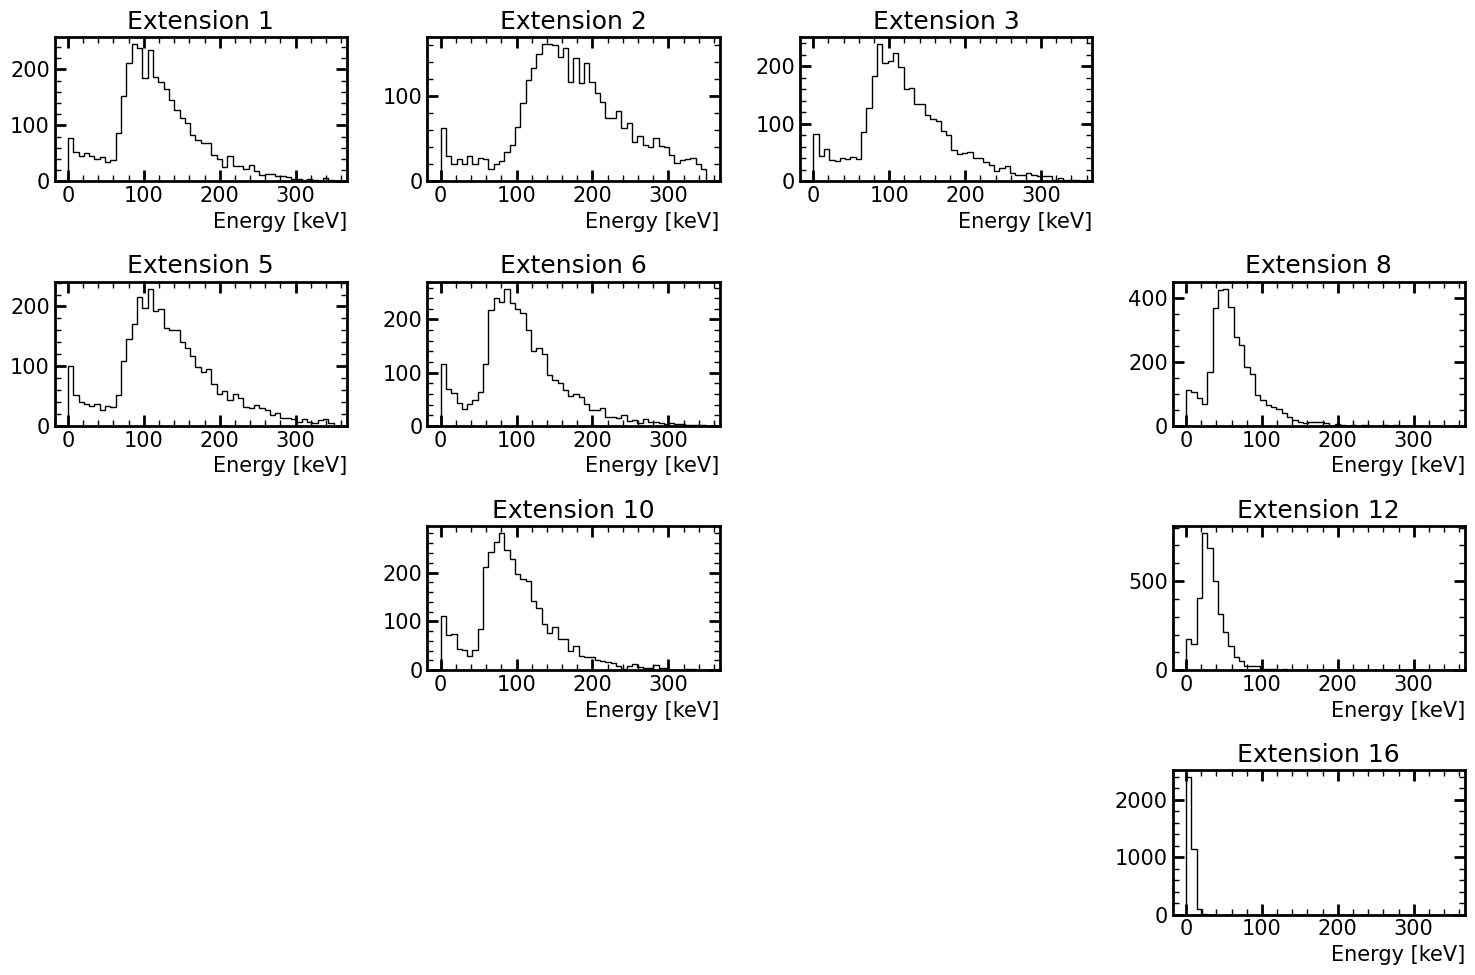

In [121]:
CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)
ratio_keV_elec = 0.00368

BINS = 50
plot_range = (0, 350)

plt.figure(figsize = [15,10])
for ext in CCD_array:
    if ext in CCD_bad:
        continue
    list_chargeDep = []
    muon_chargeDep  = data_histogram_all[f'extension_{ext}']['muons']["charge_muons"]

    for element in muon_chargeDep:
        list_chargeDep.append(element*ratio_keV_elec)

    plt.subplot(4,4,ext)
    plt.hist(list_chargeDep, bins = BINS, color = 'k',  histtype = 'step',range= (plot_range[0], plot_range[1]))
    plt.title('Extension '+str(ext))
    # axs.ylabel('Y_pix')
    plt.xlabel('Energy [keV]')

    ## Escala Log
    # plt.yscale('log')

# plt.legend()

## EScala Normal
# axs.set_ylim(0,200)
# axs.set_xlim(0,190000)

plt.tight_layout()
plt.show()

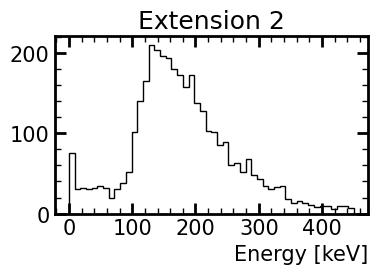

In [120]:
label = 1
ext = 2

CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
# CCD_arrayOfficial = (1,2,5,6,7,9,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)
ratio_keV_elec = 0.00368

BINS = 50
plot_range = (0, 450)
# plot_range = (0, 120000)

plt.figure(figsize = [15,10])

list_chargeDep = []
muon_chargeDep  = data_histogram_all[f'extension_{ext}']['muons']["charge_muons"]

for element in muon_chargeDep:
    list_chargeDep.append(element*ratio_keV_elec)
    # list_chargeDep.append(element)

plt.subplot(4,4,ext)
plt.hist(list_chargeDep, bins = BINS, color = 'k',  histtype = 'step',range= (plot_range[0], plot_range[1]))
plt.title('Extension '+str(ext))
# axs.ylabel('Y_pix')
plt.xlabel('Energy [keV]')
# plt.xlabel('Charge [e-]')

## Escala Log
# plt.yscale('log')

# plt.legend()

## EScala Normal
# axs.set_ylim(0,200)
# axs.set_xlim(0,190000)

plt.tight_layout()
plt.show()


In [115]:
# min_oScan = np.min(true_Oscan)
# extension = 4
Bins = 100
Bins_fit = Bins
Range_fit_1 = [97, 300]
# Range_fit_1 = [40000, 60000]

# data = hdu_list[extension-1].data[:, :550]
data = list_chargeDep
# data = charge_ext1

fgaus_fir = TF1("","landau", Range_fit_1[0], Range_fit_1[1], 2) # TF1("nombre", "funcion escrita como en root", min, max, #parametros)
fgaus_Fepeak = TF1("gausFe","gaus", 4.05, 4.3,3)

Range_plot = [0, Range_fit_1[1]+100]
h3=TH1F("histogram", f"Energy Deposition Distribution (from Muon Clusters)",Bins_fit, Range_plot[0], Range_plot[1])
# h3.AddDirectory(False)
for pixel_value in data:
#    print(pixel_value)
   if pixel_value != 0:
        # if not np.ma.is_masked(pixel_value):
        h3.Fill(pixel_value)
        # print(pixel_value)

# fgaus_fir.SetParameters(200, 6, 60) # Establecer parametros iniciales del fit, de manera visual es posible determinarlos como una primera aproximacion

h3.Fit(fgaus_fir, "RN")

c1=TCanvas("", "", 1000, 600)
# c1.SetLogy()
c1.SetGrid()
h3.SetStats(0)
h3.GetXaxis().SetTitle("Energy [keV]")
h3.GetYaxis().SetTitle("Events")
h3.Draw("PE")
h3.SetMarkerColor(3)
h3.SetMarkerStyle(3)
h3.SetColors(1)
h3.SetAxisRange(0,150, "Y")

# fgaus_fir.GetXaxis().SetRangeUser(-100,10000)
fgaus_fir.Draw("same")
# fgaus_Fepeak.Draw("same")
c1.Draw()

print(f"Most probable value: {fgaus_fir.GetMaximumX()} keV")
# en_scape = 4.735
en_scape =fgaus_fir.GetMaximumX()
line1 = TLine(en_scape, 0, en_scape, 100)
line1.SetLineColor(4)
line1.SetLineWidth(2)
line1.Draw()

leg = TLegend(0.1,0.7,0.48,0.9)
leg.AddEntry(h3, "Data", "PL")
# leg.AddEntry(h3, r"cal = 196.881 \pm 7.802 ADU/e")
leg.AddEntry(fgaus_fir, f"Landau Distribution Fit", "L")
leg.AddEntry(line1, f"Most probable value: {round(en_scape, 3)}", "L")
leg.Draw()

# print(fgaus_fir.GetParameters())
print('Parameters of the First Gaussian Fit')
print('Mean: ', fgaus_fir.GetParameters()[1],  ' +- ', fgaus_fir.GetParError(1))
print('Sigma: ', fgaus_fir.GetParameters()[2],  ' +- ', fgaus_fir.GetParError(2))
print("chiSquare: " + str(fgaus_fir.GetChisquare()))
print("NDegrees of Freedom: " + str(fgaus_fir.GetNDF()))
# # print("chiSquare / NDF :", fgaus2.GetChisquare() / fgaus2.GetNDF())
print("Prob:", fgaus_fir.GetProb(), '\n')


Most probable value: 146.2238807547306 keV
Parameters of the First Gaussian Fit
Mean:  152.7081180952921  +-  1.327034539661643
Sigma:  29.105621980699397  +-  0.9644934475040934
chiSquare: 50.738430674175476
NDegrees of Freedom: 48
Prob: 0.36612394204624066 

****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      50.7384
NDf                       =           48
Edm                       =  8.83241e-08
NCalls                    =          127
Constant                  =      507.421   +/-   14.2592     
MPV                       =      152.708   +/-   1.32703     
Sigma                     =      29.1056   +/-   0.964493     	 (limited)


Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).


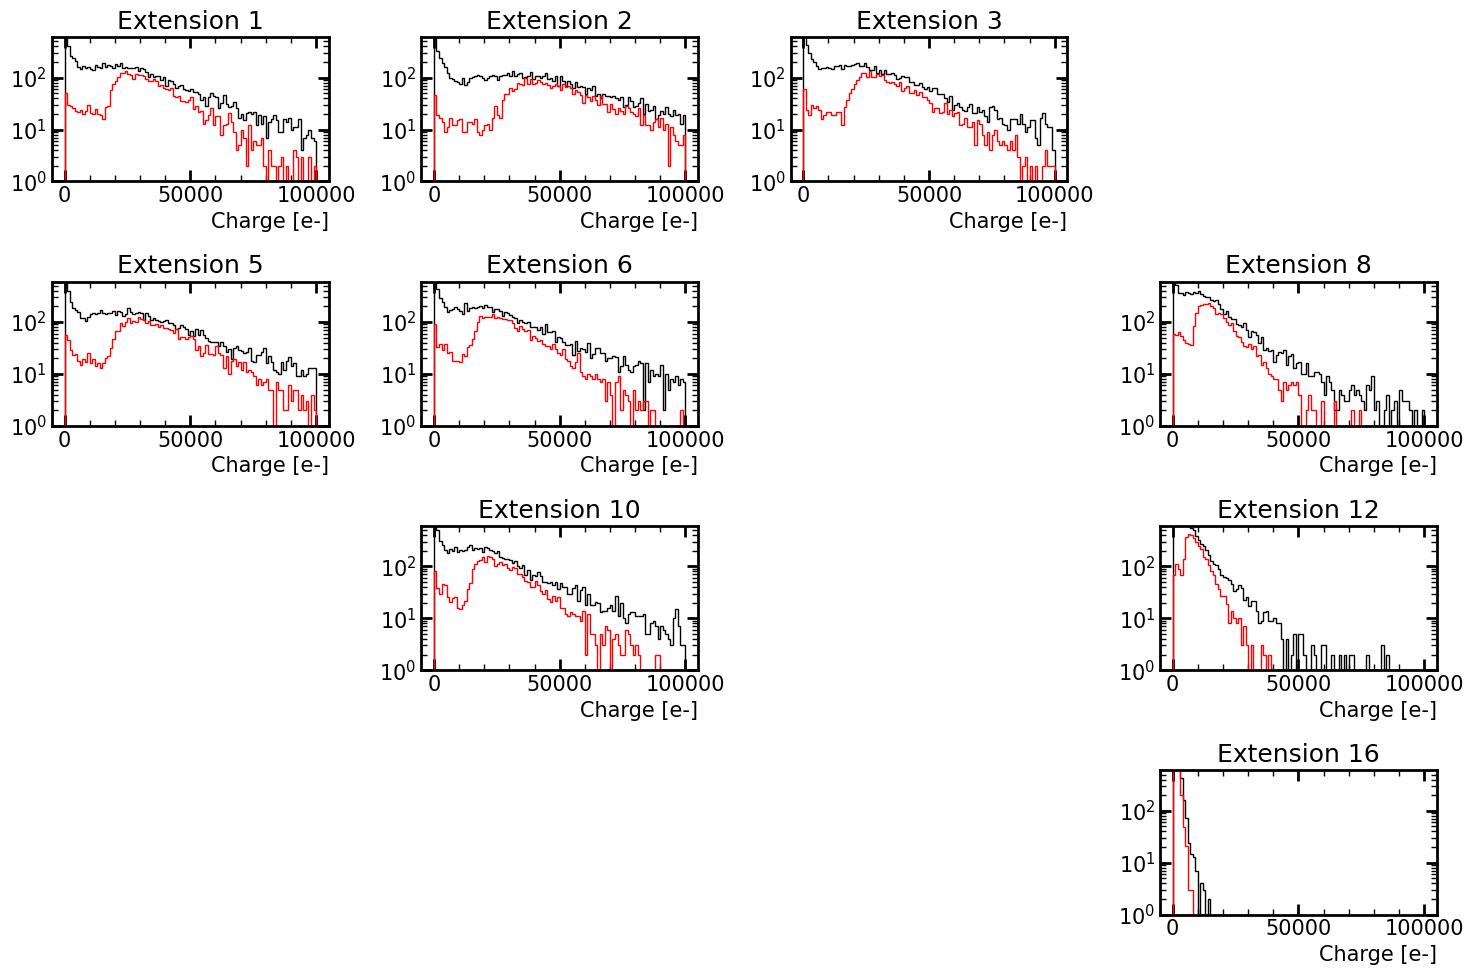

In [145]:
path_all = "./RUN214/dict_energy_ALLclusters_RUNID213_NSAMP500_NImgs_500_SIZE_420x490_NSIGMAS_5_electrons.pkl"

histogram_All = open(path_all, 'rb')
data_histogram_All = pck.load(histogram_All)
histogram_All.close()

BINS = 100
plot_range = (0, 100000)
CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)

plt.figure(figsize = [15,10])
for extension in CCD_array:
    if extension in CCD_bad:
        continue
    plt.subplot(4,4,extension)
    plt.hist(data_histogram_All[f"extension_{extension}"]["charge"], bins = BINS, color = 'k',  histtype = 'step',range= (plot_range[0], plot_range[1]),
            label = f"All clusters")
    plt.hist(data_histogram_all[f"extension_{extension}"]['muons']["charge_muons"], bins = BINS, color = 'r',  histtype = 'step',range= (plot_range[0], plot_range[1]),
             label="Muon clusters")
    plt.title('Extension '+str(extension))
    # axs.ylabel('Y_pix')
    plt.xlabel('Charge [e-]')
    # plt.legend()
    ## Escala Log
    plt.yscale('log')
    if ext in (8, 12,16):
        plt.ylim(10**0, 600)
    else: 
        plt.ylim(10**0, 300)

# plt.legend()

## EScala Normal
# axs.set_ylim(0,200)
# axs.set_xlim(0,190000)
plt.tight_layout()
plt.show()

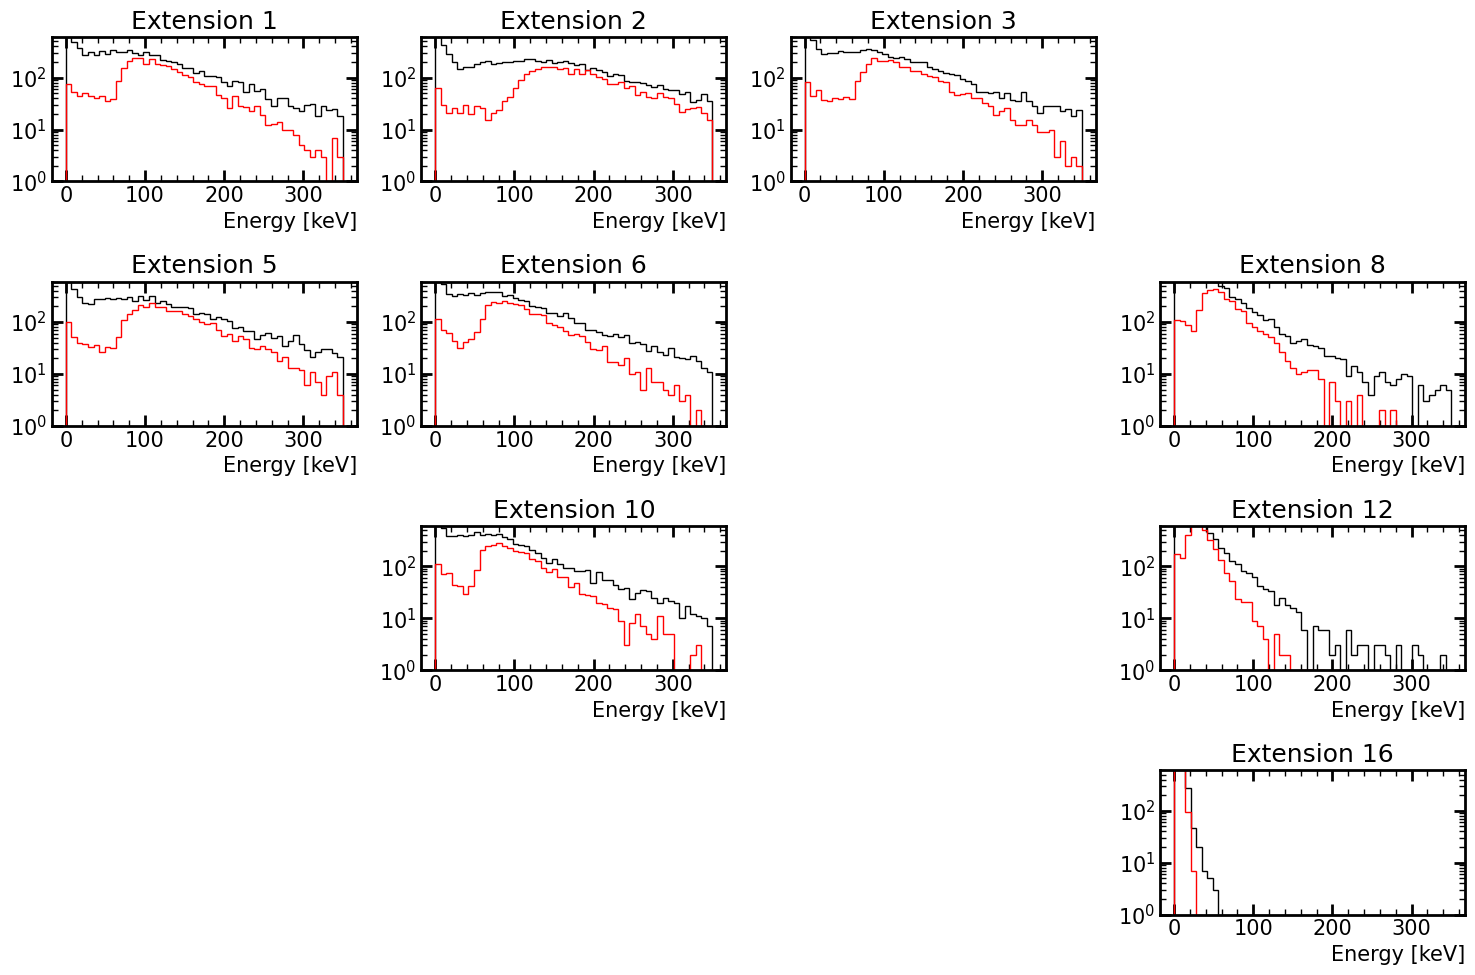

In [146]:
path_all = "./RUN214/dict_energy_ALLclusters_RUNID213_NSAMP500_NImgs_500_SIZE_420x490_NSIGMAS_5_electrons.pkl"

histogram_All = open(path_all, 'rb')
data_histogram_All = pck.load(histogram_All)
histogram_All.close()


CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)
ratio_keV_elec = 0.00368

BINS = 50
plot_range = (0, 350)

plt.figure(figsize = [15,10])
for ext in CCD_array:
    if ext in CCD_bad:
        continue
    list_chargeDep = []
    muon_chargeDep  = data_histogram_all[f'extension_{ext}']['muons']["charge_muons"]

    for element in muon_chargeDep:
        list_chargeDep.append(element*ratio_keV_elec)

    list_chargeDepAll = []
    all_clusters = data_histogram_All[f"extension_{ext}"]["charge"]

    for element in all_clusters:
        list_chargeDepAll.append(element*ratio_keV_elec)

    plt.subplot(4,4,ext)
    plt.hist(list_chargeDepAll, bins = BINS, color = 'k',  histtype = 'step',range= (plot_range[0], plot_range[1]))
    plt.hist(list_chargeDep, bins = BINS, color = 'r',  histtype = 'step',range= (plot_range[0], plot_range[1]))
    plt.title('Extension '+str(ext))
    # axs.ylabel('Y_pix')
    plt.xlabel('Energy [keV]')

    ## Escala Log
    plt.yscale('log')
    plt.ylim(10**0, 600)

# plt.legend()

## EScala Normal
# axs.set_ylim(0,200)
# axs.set_xlim(0,190000)

plt.tight_layout()
plt.show()

Total of elements: 32221


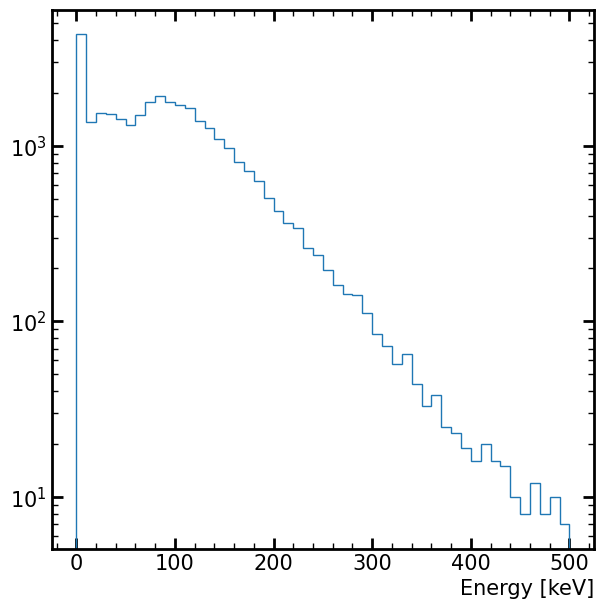

In [ ]:
list_chargeDep_allExt = []
range_plot = [0, 500]

for extension in CCD_array:
    if extension in CCD_bad:
        continue
    muon_chargeDep  = data_histogram_all[f'extension_{extension}']["muons"]["charge_muons"]
    for element in muon_chargeDep:
        list_chargeDep_allExt.append(element*ratio_keV_elec)

tot_muons = len(list_chargeDep_allExt)
print(f"Total of elements: {tot_muons}")
fig, axs = plt.subplots(1,1,figsize = [7,7])
axs.hist(list_chargeDep_allExt, bins=50, histtype="step", range=[range_plot[0],range_plot[1]])
axs.set_xlabel("Energy [keV]")
axs.set_yscale("log")
plt.show()

### Median Charge

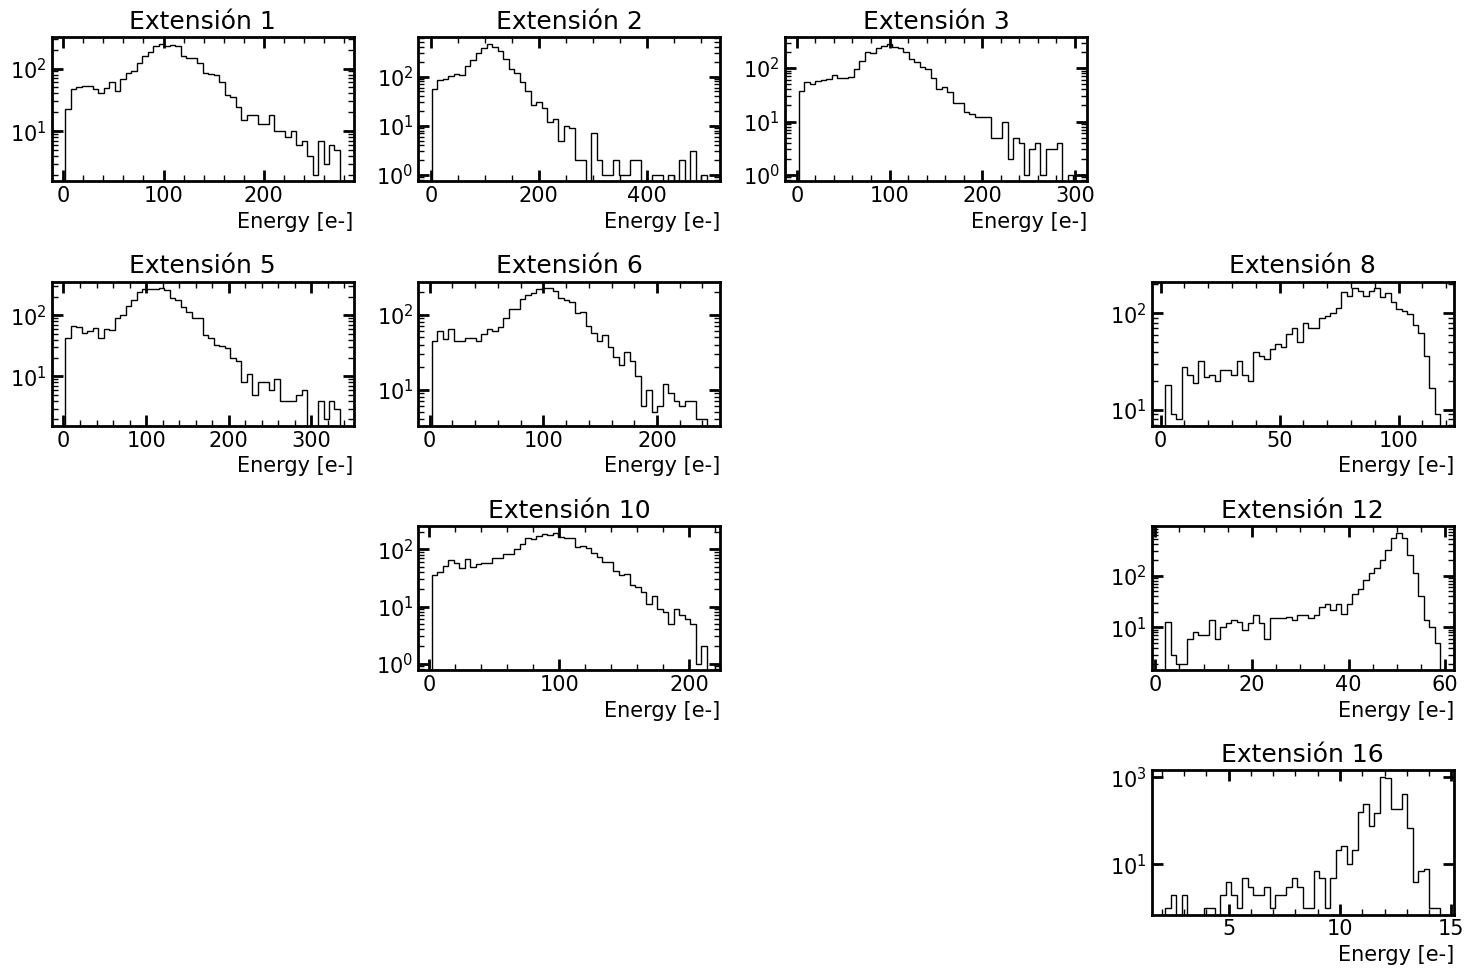

In [25]:
CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
# CCD_array = (1,2,5,6,7,9,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)

BINS = 50
plot_range = (0, 350)

plt.figure(figsize = [15,10])
for ext in CCD_array:
    if ext in CCD_bad:
        continue
    muon_chargeDep  = data_histogram_all[f'extension_{ext}']['muons']["median_charge"]

    plt.subplot(4,4,ext)
    plt.hist(muon_chargeDep, bins = BINS, color = 'k',  histtype = 'step')#,range= (plot_range[0], plot_range[1]))
    plt.title('Extensión '+str(ext))
    # axs.ylabel('Y_pix')
    plt.xlabel('Energy [e-]')

    ## Escala Log
    plt.yscale('log')

# plt.legend()

## EScala Normal
# axs.set_ylim(0,200)
# axs.set_xlim(0,190000)

plt.tight_layout()
plt.show()

### Lenght distribution

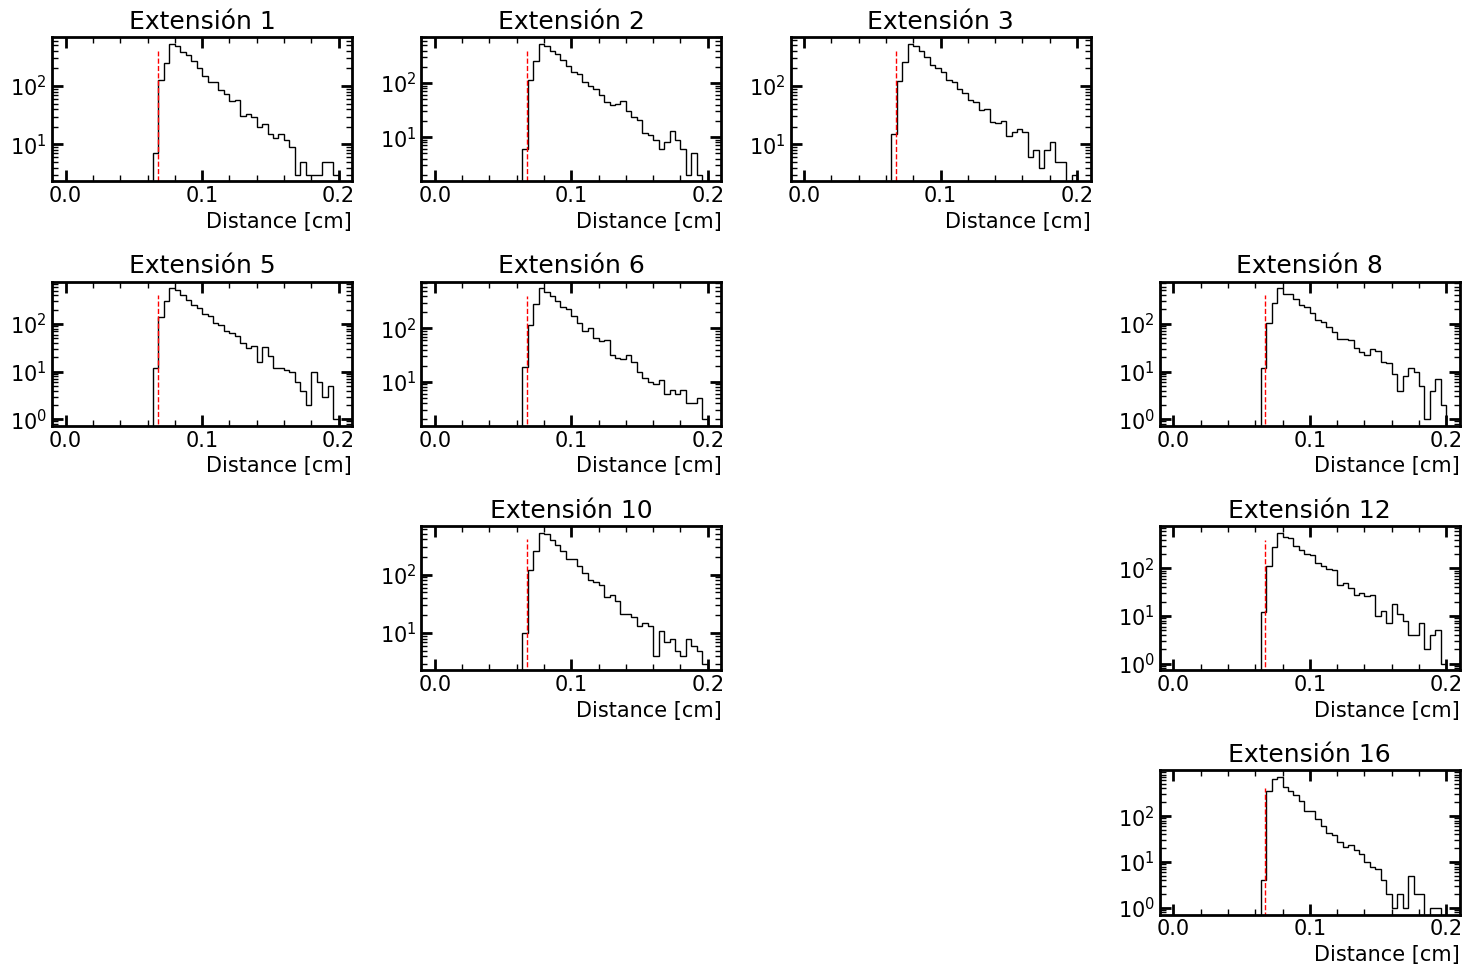

In [31]:
CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
# CCD_array = (1,2,5,6,7,9,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)

BINS = 50
plot_range = (0, 0.2)

plt.figure(figsize = [15,10])
for ext in CCD_array:
    if ext in CCD_bad:
        continue
    muon_chargeDep  = data_histogram_all[f'extension_{ext}']['muons']["l"]

    plt.subplot(4,4,ext)
    plt.hist(muon_chargeDep, bins = BINS, color = 'k',  histtype = 'step',range= (plot_range[0], plot_range[1]))
    plt.vlines(x=0.0675, ymin=0, ymax=400, color = "red", linestyles="--")
    plt.title('Extensión '+str(ext))
    # axs.ylabel('Y_pix')
    plt.xlabel('Distance [cm]')

    ## Escala Log
    plt.yscale('log')

# plt.legend()

## EScala Normal
# axs.set_ylim(0,200)
# axs.set_xlim(0,190000)

plt.tight_layout()
plt.show()

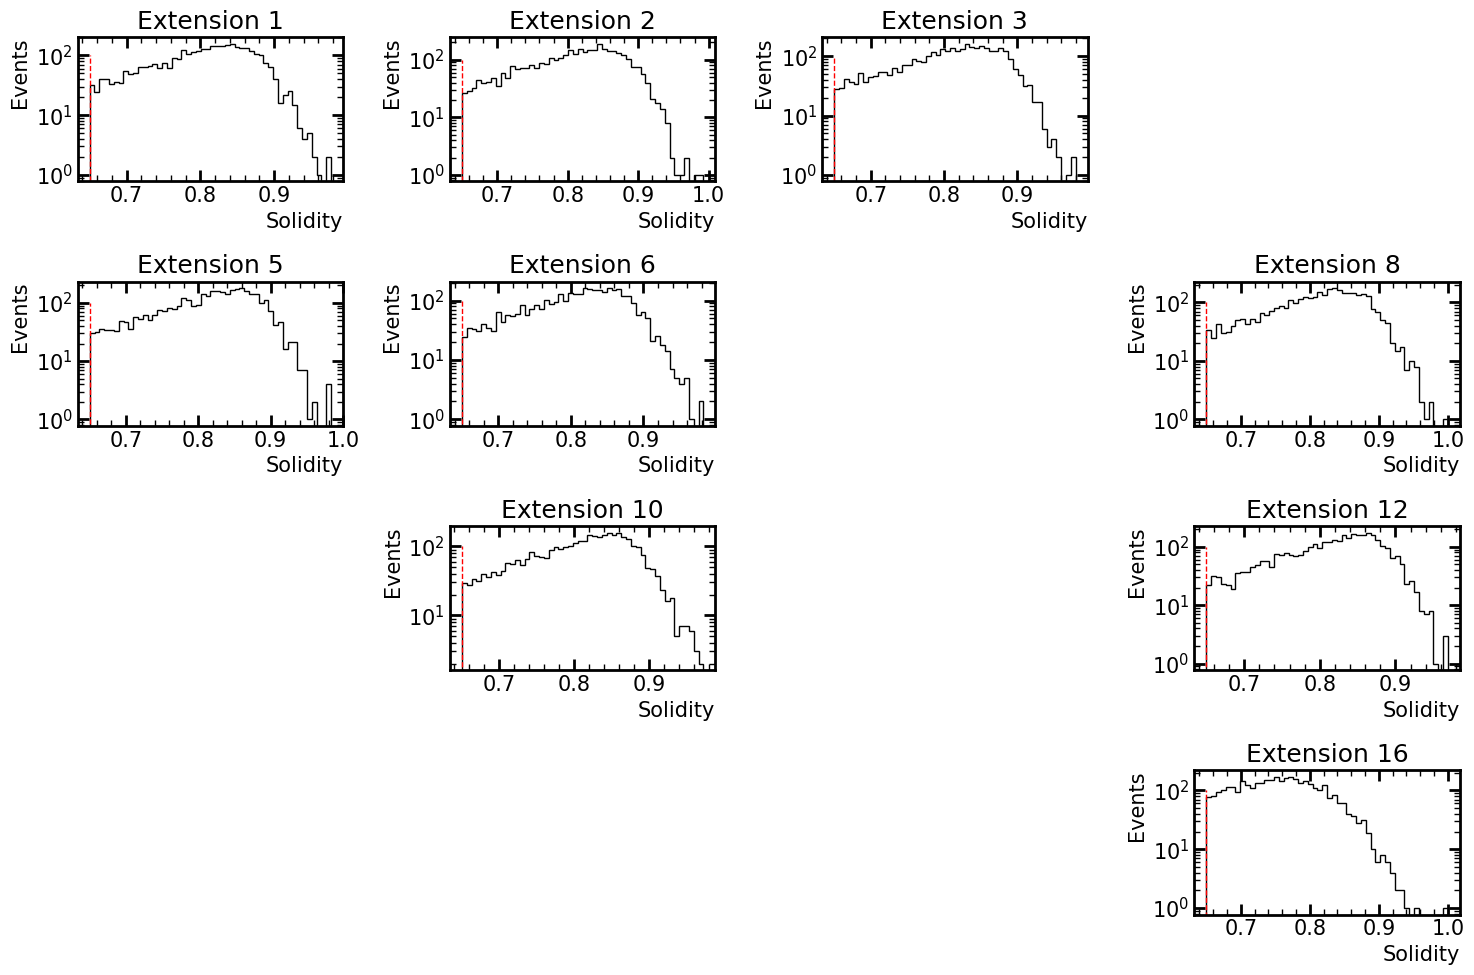

In [27]:
CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
# CCD_array = (1,2,5,6,7,9,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)

BINS = 50
plot_range = (0, 0.2)

plt.figure(figsize = [15,10])
for ext in CCD_array:
    if ext in CCD_bad:
        continue
    muon_chargeDep  = data_histogram_all[f'extension_{ext}']['muons']["sol"]

    plt.subplot(4,4,ext)
    plt.hist(muon_chargeDep, bins = BINS, color = 'k',  histtype = 'step')#,range= (plot_range[0], plot_range[1]))
    plt.vlines(x=0.65, ymin=0, ymax=100, color = "red", linestyles="--")
    plt.title('Extension '+str(ext))
    plt.ylabel('Events')
    plt.xlabel('Solidity')

    ## Escala Log
    plt.yscale('log')

# plt.legend()

## EScala Normal
# axs.set_ylim(0,200)
# axs.set_xlim(0,190000)

plt.tight_layout()
plt.show()

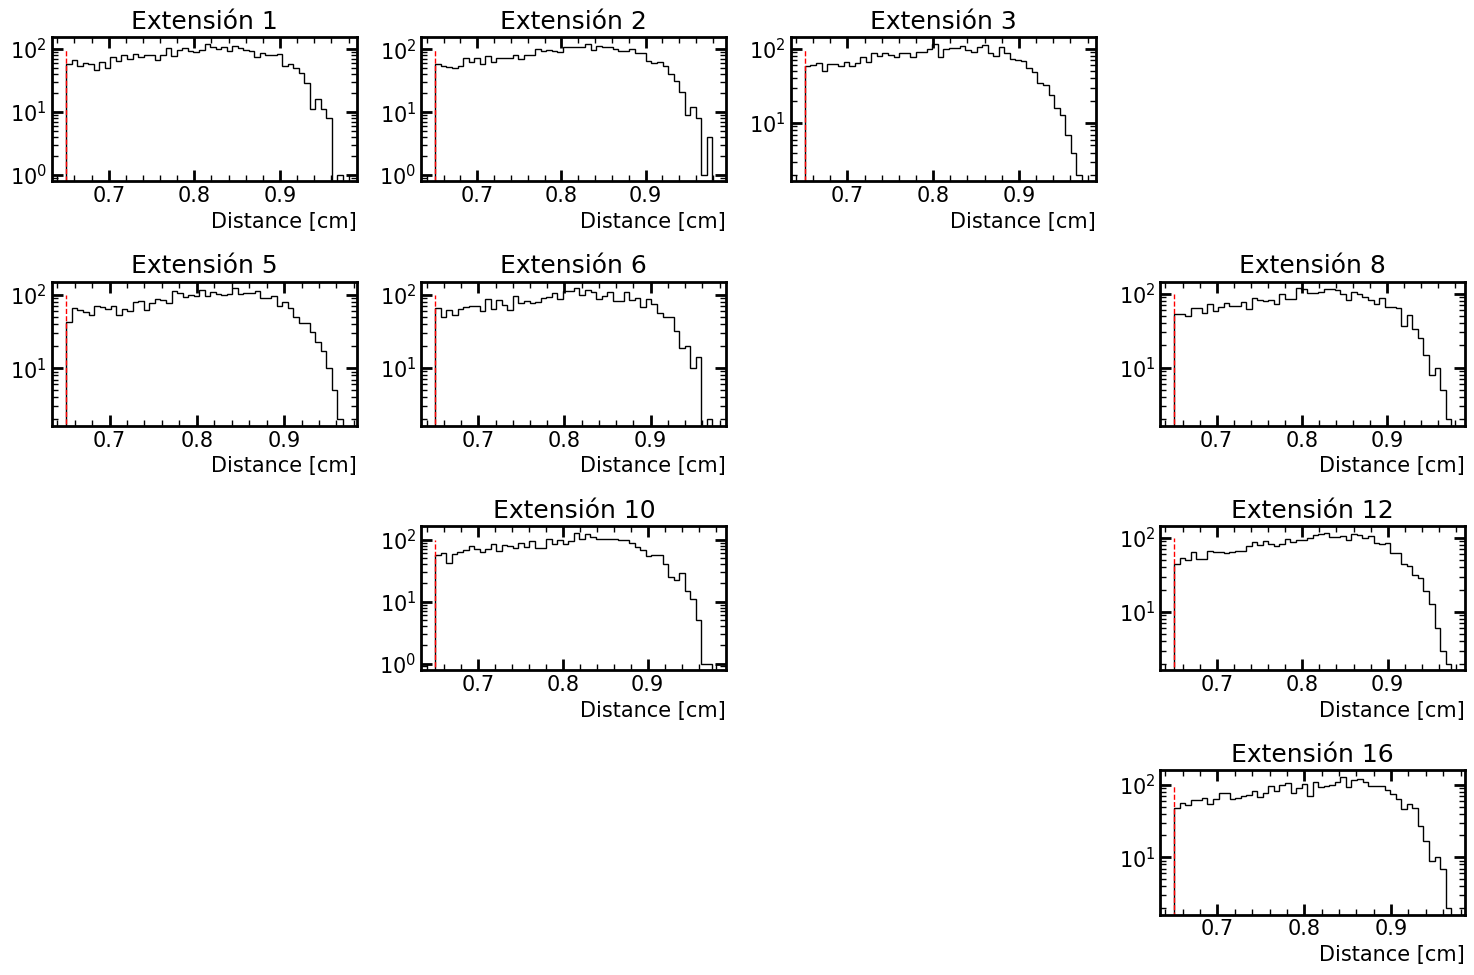

In [30]:
CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
# CCD_array = (1,2,5,6,7,9,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)

BINS = 50
plot_range = (0, 0.2)

plt.figure(figsize = [15,10])
for ext in CCD_array:
    if ext in CCD_bad:
        continue
    muon_chargeDep  = data_histogram_all[f'extension_{ext}']['muons']["elip"]

    plt.subplot(4,4,ext)
    plt.hist(muon_chargeDep, bins = BINS, color = 'k',  histtype = 'step')#,range= (plot_range[0], plot_range[1]))
    plt.vlines(x=0.65, ymin=0, ymax=100, color = "red", linestyles="--")
    plt.title('Extensión '+str(ext))
    # axs.ylabel('Y_pix')
    plt.xlabel('Distance [cm]')

    ## Escala Log
    plt.yscale('log')

# plt.legend()

## EScala Normal
# axs.set_ylim(0,200)
# axs.set_xlim(0,190000)

plt.tight_layout()
plt.show()